In [13]:
import os

chemin = "/content/extrait.mp3"

print("Le fichier existe :", os.path.exists(chemin))

Le fichier existe : False


In [2]:
!pip install -q gdown #sert à installer un outil qui permet de télécharger des fichiers depuis Google Drive vers Google Cola

In [3]:
# Supprimer l'ancienne copie du fichier ZIP dans Colab, si elle existe
!rm -f PROJET_SID_2026.zip

# Télécharger le fichier depuis Google Drive et l'enregistrer sous le nom PROJET_SID_2026.zip
!gdown --fuzzy "https://drive.google.com/file/d/1ykUsEsbMoMlsji4eewSPVgUgqjT98GJH/view?usp=drive_link" -O PROJET_SID_2026.zip

Downloading...
From (original): https://drive.google.com/uc?id=1ykUsEsbMoMlsji4eewSPVgUgqjT98GJH
From (redirected): https://drive.google.com/uc?id=1ykUsEsbMoMlsji4eewSPVgUgqjT98GJH&confirm=t&uuid=16cdb1dd-226c-484b-bc57-f533d520bad1
To: /content/PROJET_SID_2026.zip
100% 4.00G/4.00G [01:04<00:00, 61.9MB/s]


In [4]:
# Créer le dossier /content/data s'il n'existe pas déjà
!mkdir -p /content/data

# Décompresser l'archive ZIP dans le dossier /content/data
!unzip -q /content/PROJET_SID_2026.zip -d /content/data

In [5]:
!ls /content/data
!ls /content/data/*

__MACOSX  PROJET_SID_2026
/content/data/__MACOSX:
PROJET_SID_2026

/content/data/PROJET_SID_2026:
movie


In [6]:
import os

ROOT = "/content/data/PROJET_SID_2026/movie"
DOSSIER_AUDIO = os.path.join(ROOT, "audio")

print("Dossier audio trouvé :", os.path.exists(DOSSIER_AUDIO))
print("Contenu :", os.listdir(DOSSIER_AUDIO)[:10])

Dossier audio trouvé : True
Contenu : ['00089', '00186', '00220', '00209', '00036', '00271', '00045', '00337', '00174', '00298']


In [7]:
import glob, os

mp3s = sorted(glob.glob(os.path.join(DOSSIER_AUDIO, "**", "*.mp3"), recursive=True))
mp3s = [p for p in mp3s if not os.path.basename(p).startswith("._")]  # fichiers parasites macOS

print(len(mp3s), "MP3 trouvés")
print(len(os.listdir(DOSSIER_AUDIO)), "dossiers de films")
for p in mp3s[:5]:
    print(p)

noms = [os.path.basename(p) for p in mp3s]
print("Noms uniques :", len(set(noms)) == len(noms))

3088 MP3 trouvés
350 dossiers de films
/content/data/PROJET_SID_2026/movie/audio/00000/00000_clip_001.mp3
/content/data/PROJET_SID_2026/movie/audio/00000/00000_clip_002.mp3
/content/data/PROJET_SID_2026/movie/audio/00000/00000_clip_006.mp3
/content/data/PROJET_SID_2026/movie/audio/00000/00000_clip_009.mp3
/content/data/PROJET_SID_2026/movie/audio/00000/00000_clip_012.mp3
Noms uniques : True


**lister les MP3 (déjà faite, rappel)**

In [8]:
import glob, os

# Chercher tous les fichiers .mp3, y compris dans les sous-dossiers (un par film)
mp3s = sorted(glob.glob(os.path.join(DOSSIER_AUDIO, "**", "*.mp3"), recursive=True))

# Écarter les fichiers parasites créés par macOS (leur nom commence par "._")
mp3s = [p for p in mp3s if not os.path.basename(p).startswith("._")]

print(len(mp3s), "MP3 trouvés")

3088 MP3 trouvés


**installer les bibliothèques**

In [ ]:
# librosa : lecture et rééchantillonnage de l'audio
# soundfile : écriture des fichiers WAV
# joblib : exécution en parallèle (plusieurs fichiers à la fois)
# tqdm : barre de progression
!pip install -q librosa soundfile joblib tqdm

**convertir les MP3 en WAV 16 kHz mono**

In [ ]:
import librosa, soundfile as sf
from joblib import Parallel, delayed
from tqdm import tqdm

# Dossier de sortie sur le disque local de Colab (plus rapide que le Drive)
DST = "/content/wav16k"
os.makedirs(DST, exist_ok=True)

def convert(path):
    """Convertit un MP3 en WAV mono à 16 kHz et renvoie un statut."""
    # Le nom du WAV est identique à celui du MP3 (ex : 00000_clip_001.wav)
    nom = os.path.splitext(os.path.basename(path))[0]
    out = os.path.join(DST, nom + ".wav")

    # Si le WAV existe déjà, on ne le refait pas
    # (permet de relancer la cellule après une coupure de Colab)
    if os.path.exists(out):
        return "deja_fait"

    try:
        # Charger l'audio en forçant : 16 kHz (sr=16000) et un seul canal (mono=True)
        y, _ = librosa.load(path, sr=16000, mono=True)
        # Écrire le signal obtenu dans un fichier WAV à 16 kHz
        sf.write(out, y, 16000)
        return "ok"
    except Exception as e:
        # En cas de problème, on garde la trace du fichier fautif sans tout arrêter
        return f"erreur: {path} ({e})"

# Lancer la conversion sur les 3 088 fichiers, 4 à la fois
results = Parallel(n_jobs=4)(delayed(convert)(p) for p in tqdm(mp3s))

# Faire le bilan : combien de réussites, et quels fichiers ont posé problème
errors = [r for r in results if r.startswith("erreur")]
print(results.count("ok"), "convertis,", len(errors), "erreurs")
for e in errors:
    print(e)

**vérifier le résultat**

In [ ]:
# Lister les WAV créés et comparer leur nombre à celui des MP3
wavs = sorted(glob.glob(DST + "/*.wav"))
print(len(wavs), "WAV pour", len(mp3s), "MP3")   # les deux nombres doivent être égaux

# Contrôler le format des 5 premiers fichiers
for p in wavs[:5]:
    i = sf.info(p)
    # On attend : 16000 Hz, 1 canal (mono), environ 5 secondes
    print(os.path.basename(p), i.samplerate, i.channels, round(i.duration, 2), "s")

**copier les WAV sur Google Drive**

In [ ]:
from google.colab import drive

# Connecter Google Drive à Colab
drive.mount("/content/drive")

# Créer le dossier du projet sur le Drive, s'il n'existe pas
!mkdir -p /content/drive/MyDrive/projet_emovid

# Copier tout le dossier des WAV vers le Drive (les fichiers de /content
# disparaissent à la fin de la session, d'où cette copie)
!cp -r /content/wav16k /content/drive/MyDrive/projet_emovid/

# Vérifier que la copie est complète
!ls /content/drive/MyDrive/projet_emovid/wav16k | wc -l

**installer les bibliothèques et vérifier le GPU**

In [20]:
# transformers : fournit les modèles pré-entraînés (wav2vec2, HuBERT...)
!pip install -q transformers soundfile

import torch

# Vérifier si un GPU est disponible (sinon le calcul se fera sur CPU, plus lent)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Calcul sur :", device)

Calcul sur : cpu


**choisir le dossier des WAV et prendre 20 clips**

In [19]:
from google.colab import drive
import os

# Reconnecter Google Drive à cette nouvelle session (autorisation à valider)
drive.mount("/content/drive")

# Vérifier que le dossier des WAV est bien visible et compter ses fichiers
chemin = "/content/drive/MyDrive/projet_emovid/wav16k"
print("Dossier trouvé :", os.path.exists(chemin))
if os.path.exists(chemin):
    print(len(os.listdir(chemin)), "fichiers")   # attendu : 3088

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dossier trouvé : True
3088 fichiers


In [15]:
import os, glob

# Utiliser les WAV locaux s'ils existent (plus rapide), sinon ceux du Drive
DOSSIER_WAV = "/content/wav16k"
if not os.path.exists(DOSSIER_WAV):
    DOSSIER_WAV = "/content/drive/MyDrive/projet_emovid/wav16k"

# Lister tous les WAV et ne garder que 20 clips pour ce test
wavs = sorted(glob.glob(os.path.join(DOSSIER_WAV, "*.wav")))
print(len(wavs), "WAV disponibles dans", DOSSIER_WAV)
echantillon = wavs[:20]

3088 WAV disponibles dans /content/wav16k


**charger le modèle wav2vec2-base**

Ce calcul ne dépend pas de la partition. On extrait donc les embeddings des 3 088 clips d’un coup, sans se soucier de train, dev ou test

In [21]:
from transformers import AutoFeatureExtractor, AutoModel

NOM_MODELE = "facebook/wav2vec2-base"

# Le "feature extractor" prépare le signal pour le modèle (normalisation du volume)
fe = AutoFeatureExtractor.from_pretrained(NOM_MODELE)

# Charger le modèle, l'envoyer sur le GPU et le passer en mode "évaluation"
# (eval() désactive les comportements propres à l'entraînement, comme le dropout)
model = AutoModel.from_pretrained(NOM_MODELE).to(device).eval()

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_hid.bias             | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


**fonction qui calcule l’embedding d’un clip**

In [22]:
import numpy as np
import soundfile as sf

def embedding(chemin):
    """Renvoie un tableau (nb_couches, 768) : un vecteur par couche du modèle."""
    # Lire le signal audio (déjà en 16 kHz mono grâce à la conversion)
    signal, sr = sf.read(chemin)
    assert sr == 16000, f"Fréquence inattendue : {sr}"

    # Préparer l'entrée du modèle
    entree = fe(signal, sampling_rate=16000, return_tensors="pt").to(device)

    # no_grad : on ne calcule pas de gradients, car on n'entraîne pas le modèle
    with torch.no_grad():
        sortie = model(**entree, output_hidden_states=True)

    # hidden_states = sortie de chaque couche : 13 tenseurs (1, nb_pas_de_temps, 768)
    couches = torch.stack(sortie.hidden_states)      # (13, 1, T, 768)

    # Moyenne sur le temps : on résume les ~5 s du clip en un seul vecteur par couche
    return couches.squeeze(1).mean(dim=1).cpu().numpy()   # (13, 768)

**tester sur les 20 clips**

In [23]:
from tqdm import tqdm

# Calculer l'embedding de chaque clip de l'échantillon
resultats = np.stack([embedding(p) for p in tqdm(echantillon)])

# On attend : (20 clips, 13 couches, 768 dimensions)
print("Forme obtenue :", resultats.shape)

# Contrôles de base : pas de valeurs manquantes, valeurs d'ordre de grandeur raisonnable
print("Valeurs manquantes :", np.isnan(resultats).any())
print("Min / max :", resultats.min().round(2), "/", resultats.max().round(2))

100%|██████████| 20/20 [01:10<00:00,  3.53s/it]

Forme obtenue : (20, 13, 768)
Valeurs manquantes : False
Min / max : -1.98 / 1.78


**copier les WAV du Drive vers le disque local**

In [24]:
import os, shutil

SRC = "/content/drive/MyDrive/projet_emovid/wav16k"   # WAV sur le Drive
LOCAL = "/content/wav16k"                             # copie locale, plus rapide à lire

# Copier une seule fois (si le dossier local existe déjà, on ne refait pas la copie)
if not os.path.exists(LOCAL):
    shutil.copytree(SRC, LOCAL)

print(len(os.listdir(LOCAL)), "WAV en local")   # attendu : 3088

3088 WAV en local


**extraire les embeddings des trois modèles**

In [25]:
import glob, numpy as np, soundfile as sf, torch
from tqdm import tqdm
from transformers import AutoFeatureExtractor, AutoModel

device = "cuda" if torch.cuda.is_available() else "cpu"

# Dossier de sortie sur le Drive (les résultats doivent survivre à la session)
SORTIE = "/content/drive/MyDrive/projet_emovid/embeddings"
os.makedirs(SORTIE, exist_ok=True)

# Liste triée de tous les clips : l'ordre est fixe, donc identique pour tous les modèles
wavs = sorted(glob.glob(LOCAL + "/*.wav"))
ids = [os.path.splitext(os.path.basename(p))[0] for p in wavs]

# Sauvegarder la liste des identifiants : ligne i du tableau = clip ids[i]
with open(f"{SORTIE}/ids.txt", "w") as f:
    f.write("\n".join(ids))

# Les trois modèles de parole à utiliser
MODELES = {
    "wav2vec2_base": "facebook/wav2vec2-base",
    "hubert_base": "facebook/hubert-base-ls960",
    "wav2vec2_emotion": "superb/wav2vec2-base-superb-er",
}

for nom, repo in MODELES.items():
    fichier = f"{SORTIE}/{nom}.npy"

    # Si ce modèle a déjà été traité, on passe au suivant (reprise après coupure)
    if os.path.exists(fichier):
        print(nom, ": déjà fait")
        continue

    print("Extraction :", nom)
    fe = AutoFeatureExtractor.from_pretrained(repo)
    model = AutoModel.from_pretrained(repo).to(device).eval()

    resultats = []
    for p in tqdm(wavs):
        signal, sr = sf.read(p)
        entree = fe(signal, sampling_rate=16000, return_tensors="pt").to(device)
        with torch.no_grad():
            sortie = model(**entree, output_hidden_states=True)
        # (13 couches, 768) : moyenne sur le temps pour chaque couche
        couches = torch.stack(sortie.hidden_states).squeeze(1).mean(dim=1)
        resultats.append(couches.cpu().numpy())

    tableau = np.stack(resultats)                 # (3088, 13, 768)
    np.save(fichier, tableau)                     # sauvegarde sur le Drive
    print(nom, "->", tableau.shape, "| valeurs manquantes :", np.isnan(tableau).any())

    # Libérer la mémoire du GPU avant le modèle suivant
    del model
    torch.cuda.empty_cache()

wav2vec2_base : déjà fait
hubert_base : déjà fait
wav2vec2_emotion : déjà fait


**relier les embeddings aux émotions et à la partition**

In [26]:
import os, glob, json
import pandas as pd

ROOT = "/content/data/PROJET_SID_2026/movie"
print("Contenu de movie :", os.listdir(ROOT))   # pour voir où sont rangés les JSON

# Chercher tous les JSON (un par clip), dans tous les sous-dossiers
jsons = sorted(glob.glob(os.path.join(ROOT, "**", "*.json"), recursive=True))
jsons = [p for p in jsons if not os.path.basename(p).startswith("._")]   # fichiers parasites macOS
print(len(jsons), "JSON trouvés")
print("Exemple :", jsons[:2])

# Lire chaque JSON : on garde l'identifiant du clip et son émotion
lignes = []
for p in jsons:
    with open(p) as f:
        d = json.load(f)
    lignes.append({"video_id": d["video_id"], "emotion": d["emotion"]})
labels = pd.DataFrame(lignes).drop_duplicates("video_id")

# Identifiant du film = début du nom du clip (ex : 00000_clip_001 -> 00000)
labels["film_id"] = labels["video_id"].str.split("_clip").str[0]

# Rattacher la partition (lire film_id en texte pour garder les zéros initiaux)
split = pd.read_csv("/content/drive/MyDrive/projet_emovid/Group_1.csv", dtype={"film_id": str})
split["film_id"] = split["film_id"].str.zfill(5)
labels = labels.merge(split, on="film_id", how="left")

# Contrôles : tous les clips doivent avoir un split
print("Clips sans split :", labels["split"].isna().sum())     # attendu : 0
print(labels["split"].value_counts())
print(pd.crosstab(labels["split"], labels["emotion"]))

# Aligner avec l'ordre des embeddings (ids.txt) et sauvegarder
ids = open("/content/drive/MyDrive/projet_emovid/embeddings/ids.txt").read().split("\n")
labels = labels.set_index("video_id").loc[ids].reset_index()
labels.to_csv("/content/drive/MyDrive/projet_emovid/labels.csv", index=False)
print(len(labels), "lignes sauvegardées dans labels.csv")   # attendu : 3088

Contenu de movie : ['video', 'audio', 'annotation', '.DS_Store']
3088 JSON trouvés
Exemple : ['/content/data/PROJET_SID_2026/movie/annotation/00000/00000_clip_001.json', '/content/data/PROJET_SID_2026/movie/annotation/00000/00000_clip_002.json']
Clips sans split : 0
split
train    2207
dev       442
test      439
Name: count, dtype: int64
emotion  amusement  anger  awe  contentment  disgust  excitement  fear  \
split                                                                    
dev             35     98   40           54       43          51    74   
test            35     96   40           54       43          51    74   
train          174    483  206          265      211         252   371   

emotion  sadness  
split             
dev           47  
test          46  
train        245  
3088 lignes sauvegardées dans labels.csv


La vérification de la partition est concluante : aucun clip n’est sans ensemble, et les effectifs sont cohérents (2 207 clips en entraînement, 442 en développement et 439 en test, soit 3 088 au total). Les ensembles de développement et de test sont très proches l’un de l’autre (par exemple 35 clips d’amusement dans chacun, 98 contre 96 pour anger et 74 dans chacun pour fear), ce qui signifie que les réglages effectués sur le développement seront représentatifs du test. Les classes sont toutefois déséquilibrées, et la partition du groupe 1 conserve ce déséquilibre : sur l’ensemble du corpus, anger représente environ 22 % des clips (677), fear 17 %, contentment 12 %, excitement et sadness 11 % chacune, disgust 10 %, awe 9 % et amusement 8 % (244 clips). Il faut en tenir compte pour interpréter les scores : un modèle qui prédirait toujours anger obtiendrait une accuracy d’environ 22 % mais une macro-F1 très faible, et un tirage uniforme au hasard donne environ 12,5 %. La macro-F1 doit donc être nettement supérieure à ces repères pour conclure que les embeddings sont informatifs. Enfin, la classe amusement ne compte que 35 clips en développement et en test : son score propre sera très sensible à quelques erreurs et doit être interprété avec prudence.

**Classifieur par couche (approfondissement)**

Chaque modèle (wav2vec2, HuBERT...) est composé de 12 couches empilées, et chaque couche transforme le son un peu différemment. Les premières capturent plutôt des caractéristiques acoustiques simples (timbre, énergie), les dernières des informations plus abstraites. Avec la couche 0 (l’entrée), on obtient 13 représentations possibles du même clip. On ne sait pas à l’avance laquelle contient le plus d’information sur l’émotion.

In [27]:
#Pour chaque modèle et chaque couche (0 à 12), on entraîne une régression logistique sur train et
# on mesure la macro-F1 sur dev. Le test n’est pas utilisé ici.
#On combine les 13 couches de HuBERT par une moyenne pour essayer d’obtenir une représentation audio qui
#  rassemble les informations apprises à différents niveaux du modèle.
import numpy as np, pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score
from tqdm import tqdm

DRIVE = "/content/drive/MyDrive/projet_emovid"

# Étiquettes et partition, dans le même ordre que les embeddings
labels = pd.read_csv(f"{DRIVE}/labels.csv", dtype={"film_id": str})
y = labels["emotion"].values

# Masques booléens : quels clips appartiennent à train / dev
est_train = (labels["split"] == "train").values
est_dev = (labels["split"] == "dev").values

MODELES = ["wav2vec2_base", "hubert_base", "wav2vec2_emotion"]
scores = {}   # nom du modèle -> liste de 13 macro-F1 (une par couche)

for nom in MODELES:
    # Charger les embeddings : (3088 clips, 13 couches, 768 dimensions)
    X = np.load(f"{DRIVE}/embeddings/{nom}.npy")
    scores[nom] = []

    for couche in tqdm(range(13), desc=nom):
        Xc = X[:, couche, :]                       # (3088, 768) : une seule couche

        # Standardiser : moyenne et écart-type calculés sur le TRAIN uniquement
        sc = StandardScaler().fit(Xc[est_train])
        Xtr = sc.transform(Xc[est_train])
        Xdv = sc.transform(Xc[est_dev])

        # Régression logistique ; class_weight="balanced" compense les classes rares
        clf = LogisticRegression(C=0.1, max_iter=2000, class_weight="balanced")
        clf.fit(Xtr, y[est_train])

        # Macro-F1 sur dev : moyenne des F1 des 8 émotions, sans privilégier les grosses classes
        f1 = f1_score(y[est_dev], clf.predict(Xdv), average="macro")
        scores[nom].append(f1)

# Résumé : meilleure couche de chaque modèle
for nom in MODELES:
    meilleure = int(np.argmax(scores[nom]))
    print(f"{nom}: meilleure couche = {meilleure}, macro-F1 dev = {scores[nom][meilleure]:.3f}")

wav2vec2_emotion: 100%|██████████| 13/13 [01:11<00:00,  5.49s/it]

wav2vec2_base: meilleure couche = 0, macro-F1 dev = 0.230
hubert_base: meilleure couche = 2, macro-F1 dev = 0.238
wav2vec2_emotion: meilleure couche = 1, macro-F1 dev = 0.221


**Courbe pour la présentation**

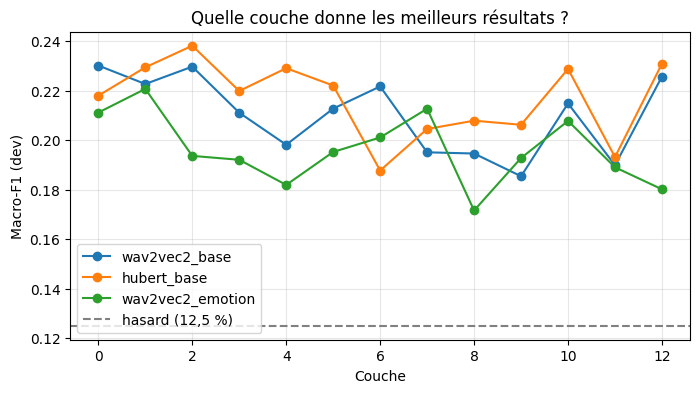

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
for nom in MODELES:
    plt.plot(range(13), scores[nom], marker="o", label=nom)
plt.axhline(1/8, color="gray", linestyle="--", label="hasard (12,5 %)")   # repère du hasard
plt.xlabel("Couche")
plt.ylabel("Macro-F1 (dev)")
plt.title("Quelle couche donne les meilleurs résultats ?")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(f"{DRIVE}/courbe_couches.png", dpi=150, bbox_inches="tight")
plt.show()

Les trois modèles dépassent le hasard (12,5 %) avec une macro-F1 comprise entre 0,17 et 0,24, mais le signal est faible et aucune couche ne se détache clairement. Le meilleur point est HuBERT à la couche 2 (≈ 0,24), devant HuBERT aux couches 10 et 12 et wav2vec2-base aux couches 0, 2 et 12 (≈ 0,23). Les écarts entre couches sont du même ordre que le bruit : avec 442 clips en dev, dont seulement 35 pour amusement, quelques prédictions suffisent à faire bouger la macro-F1 de plusieurs points. On peut dire que HuBERT est légèrement devant wav2vec2-base, sans certitude. Le modèle wav2vec2_emotion, pourtant entraîné à reconnaître des émotions, est le moins bon, probablement parce qu’il a été appris sur de la parole jouée en studio, très différente des extraits de films (musique, bruitages, ambiance). Ces scores modestes s’expliquent par le fait que l’émotion d’une scène passe aussi par l’image, la musique et le contenu des dialogues, pas seulement par la voix. Enfin, choisir la meilleure couche sur dev rend son score un peu optimiste : seul le test, regardé une fois à la fin, donne une estimation honnête.

**Test du surapprentissage (Overfitting)**

In [29]:

# Test du surapprentissage : HuBERT, couche 2

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# Charger les données
DRIVE = "/content/drive/MyDrive/projet_emovid"
labels = pd.read_csv(f"{DRIVE}/labels.csv", dtype={"film_id": str})
X = np.load(f"{DRIVE}/embeddings/hubert_base.npy")
y = labels["emotion"].values

# Séparer train et dev
est_train = (labels["split"] == "train").values
est_dev = (labels["split"] == "dev").values

# Sélectionner la couche 2
Xc = X[:, 2, :]

# Standardiser uniquement à partir du train
scaler = StandardScaler()
X_train = scaler.fit_transform(Xc[est_train])
X_dev = scaler.transform(Xc[est_dev])

y_train = y[est_train]
y_dev = y[est_dev]

# Entraîner le classifieur
model = LogisticRegression(
    C=0.1,
    max_iter=2000,
    class_weight="balanced"
)
model.fit(X_train, y_train)

# Prédictions sur train et dev
y_pred_train = model.predict(X_train)
y_pred_dev = model.predict(X_dev)

# Comparer les performances
resultats = pd.DataFrame({
    "Jeu de données": ["Train", "Dev"],
    "Accuracy": [
        accuracy_score(y_train, y_pred_train),
        accuracy_score(y_dev, y_pred_dev)
    ],
    "F1-macro": [
        f1_score(y_train, y_pred_train, average="macro"),
        f1_score(y_dev, y_pred_dev, average="macro")
    ]
})

display(resultats.round(3))


,Jeu de données,Accuracy,F1-macro
0,Train,0.720,0.728
1,Dev,0.253,0.238


Sur train : le modèle obtient un F1-macro de 72,8 %.
Sur dev : le F1-macro tombe à 23,8 %.

**Conclusion :**

le modèle apprend bien les données d'entraînement, mais généralise mal aux données de validation. Cet écart important est un signe de surapprentissage.

**Améliorer un peu les embeddings (sur dev)**

C’est l’étape où on peux encore gagner quelques points avec peu d’effort :

Combiner les couches (moyenne de toutes les couches, ou des premières) au lieu d’en choisir une, ce qui lisse le bruit de la courbe ;
Garder moyenne et écart-type sur le temps, au lieu de la moyenne seule ;
Régler la régularisation C (0,01, 0,1, 1) ;
éventuellement un intervalle de confiance (bootstrap) pour savoir si les écarts entre modèles sont réels.

C est un paramètre de la régression logistique qui règle la force de la régularisation, c’est-à-dire la pénalité qui empêche le modèle d’utiliser des poids trop grands pour coller au bruit des données d’entraînement (le surapprentissage). Il fonctionne à l’envers : un C petit (0,01) impose une forte pénalité et donne un modèle simple, tandis qu’un C grand (1 ou plus) laisse le modèle libre, au risque qu’il apprenne par cœur. Comme on ne peut pas deviner la bonne valeur, on en essaie plusieurs sur train et on garde celle qui donne la meilleure macro-F1 sur dev.

**préparer les outils et charger les étiquettes**

Cette cellule importe les bibliothèques, lit labels.csv (émotion et ensemble de chaque clip) et prépare les repères qui séparent les clips de train et de dev

In [30]:
import numpy as np, pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score
from tqdm import tqdm

# Dossier du projet sur le Drive
DRIVE = "/content/drive/MyDrive/projet_emovid"

# Lire le tableau des clips (dans le même ordre que les embeddings)
# dtype=str pour garder les zéros initiaux des identifiants de films
labels = pd.read_csv(f"{DRIVE}/labels.csv", dtype={"film_id": str})

# y = l'émotion de chaque clip (ce que le classifieur doit prédire)
y = labels["emotion"].values

# Masques booléens : True si le clip appartient à l'ensemble indiqué
est_train = (labels["split"] == "train").values
est_dev = (labels["split"] == "dev").values

# Contrôle : on attend 3088 clips, dont 2207 en train et 442 en dev
print(len(labels), "clips au total")
print(est_train.sum(), "en train |", est_dev.sum(), "en dev")

3088 clips au total
2207 en train | 442 en dev


**charger les embeddings d’un modèle et combiner des couches**

In [31]:
# Charger les embeddings de HuBERT : un tableau de forme (3088 clips, 13 couches, 768 dimensions)
X = np.load(f"{DRIVE}/embeddings/hubert_base.npy")
print("Forme des embeddings :", X.shape)

# Moyenne des 13 couches : on garde un seul vecteur de 768 valeurs par clip
# axis=1 correspond à l'axe des couches
Xc = X[:, :, :].mean(axis=1)
print("Forme après moyenne des couches :", Xc.shape)

# Contrôle : pas de valeur manquante
print("Valeurs manquantes :", np.isnan(Xc).any())

Forme des embeddings : (3088, 13, 768)
Forme après moyenne des couches : (3088, 768)
Valeurs manquantes : False


HuBERT obtient le meilleur résultat pour l’instant, mais l’écart est faible. Le score macro-F1 est une moyenne des performances sur les huit émotions ; un score de 0,238 reste modeste. Il faut donc poursuivre les essais avant de conclure qu’un modèle est réellement meilleur.

**entraîner un classifieur sur la moyenne des couches**

In [32]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

In [33]:
# 1. Standardiser les embeddings en utilisant uniquement le train
sc = StandardScaler().fit(Xc[est_train])

Xtr = sc.transform(Xc[est_train])
Xdv = sc.transform(Xc[est_dev])

# 2. Créer et entraîner le classifieur
clf = LogisticRegression(
    C=0.1,
    max_iter=2000,
    class_weight="balanced"
)

clf.fit(Xtr, y[est_train])

# 3. Prédire les émotions sur le jeu de développement
y_pred = clf.predict(Xdv)

# 4. Calculer le macro-F1
f1 = f1_score(y[est_dev], y_pred, average="macro")

print(f"HuBERT — moyenne des 13 couches : macro-F1 dev = {f1:.3f}")

HuBERT — moyenne des 13 couches : macro-F1 dev = 0.241


**Tester plusieurs valeurs de C**

on chercher la meilleure valeur du paramètre C de la régression logistique, en conservant la moyenne des 13 couches de HuBERT

In [34]:
# Tester différentes valeurs de C
resultats_C = []

for C in [0.001, 0.01, 0.1, 1, 10, 100]:

    # Créer le classifieur
    clf = LogisticRegression(
        C=C,
        max_iter=2000,
        class_weight="balanced"
    )

    # Entraîner sur train
    clf.fit(Xtr, y[est_train])

    # Prédire les émotions sur dev
    y_pred = clf.predict(Xdv)

    # Calculer le macro-F1
    score = f1_score(
        y[est_dev],
        y_pred,
        average="macro"
    )

    resultats_C.append((C, score))

    print(f"C = {C:<6} | Macro-F1 dev = {score:.3f}")

# Afficher le meilleur réglage
meilleur_C, meilleur_score = max(
    resultats_C,
    key=lambda resultat: resultat[1]
)

print("\nMeilleur C :", meilleur_C)
print(f"Meilleur macro-F1 dev : {meilleur_score:.3f}")

C = 0.001  | Macro-F1 dev = 0.255
C = 0.01   | Macro-F1 dev = 0.250
C = 0.1    | Macro-F1 dev = 0.241
C = 1      | Macro-F1 dev = 0.225
C = 10     | Macro-F1 dev = 0.209
C = 100    | Macro-F1 dev = 0.203

Meilleur C : 0.001
Meilleur macro-F1 dev : 0.255


**affiner la recherche autour de C = 0.001**

In [35]:
# Tester des valeurs plus petites de C
resultats_C_fins = []

for C in [0.00001, 0.00005, 0.0001, 0.0005, 0.001, 0.002]:

    clf = LogisticRegression(
        C=C,
        max_iter=2000,
        class_weight="balanced"
    )

    clf.fit(Xtr, y[est_train])
    y_pred = clf.predict(Xdv)

    score = f1_score(
        y[est_dev],
        y_pred,
        average="macro"
    )

    resultats_C_fins.append((C, score))
    print(f"C = {C:<8} | Macro-F1 dev = {score:.3f}")

meilleur_C_fin, meilleur_score_fin = max(
    resultats_C_fins,
    key=lambda resultat: resultat[1]
)

print("\nMeilleur C :", meilleur_C_fin)
print(f"Meilleur macro-F1 dev : {meilleur_score_fin:.3f}")

C = 1e-05    | Macro-F1 dev = 0.162
C = 5e-05    | Macro-F1 dev = 0.203
C = 0.0001   | Macro-F1 dev = 0.225
C = 0.0005   | Macro-F1 dev = 0.274
C = 0.001    | Macro-F1 dev = 0.255
C = 0.002    | Macro-F1 dev = 0.253

Meilleur C : 0.0005
Meilleur macro-F1 dev : 0.274


**affiner autour de 0,0005**

In [36]:
for C in [0.0002, 0.0003, 0.0004, 0.0005, 0.0006, 0.0007, 0.0008]:
    clf = LogisticRegression(
        C=C,
        max_iter=2000,
        class_weight="balanced"
    )

    clf.fit(Xtr, y[est_train])
    y_pred = clf.predict(Xdv)

    score = f1_score(y[est_dev], y_pred, average="macro")
    print(f"C = {C:<8} | Macro-F1 dev = {score:.3f}")

C = 0.0002   | Macro-F1 dev = 0.241
C = 0.0003   | Macro-F1 dev = 0.245
C = 0.0004   | Macro-F1 dev = 0.268
C = 0.0005   | Macro-F1 dev = 0.274
C = 0.0006   | Macro-F1 dev = 0.256
C = 0.0007   | Macro-F1 dev = 0.255
C = 0.0008   | Macro-F1 dev = 0.261


**Conclusion provisoire :** Nous retenons C = 0,0005 pour la suite des comparaisons sur le jeu de développement. Ce choix reste à confirmer par l’évaluation finale sur le jeu de test, qui ne doit pas servir au réglage du modèle.

**Tester les 13 couches individuellement**

In [37]:
# Comparer les 13 couches individuelles de HuBERT
scores_couches = []

for couche in range(13):

    # Prendre une seule couche pour les 3088 extraits
    Xcouche = X[:, couche, :]

    # Standardiser avec les données train uniquement
    sc_couche = StandardScaler().fit(Xcouche[est_train])
    Xtr_couche = sc_couche.transform(Xcouche[est_train])
    Xdv_couche = sc_couche.transform(Xcouche[est_dev])

    # Entraîner le classifieur avec le meilleur C trouvé
    clf_couche = LogisticRegression(
        C=0.0005,
        max_iter=2000,
        class_weight="balanced"
    )

    clf_couche.fit(Xtr_couche, y[est_train])

    # Évaluer sur dev
    predictions = clf_couche.predict(Xdv_couche)
    score = f1_score(
        y[est_dev],
        predictions,
        average="macro"
    )

    scores_couches.append(score)
    print(f"Couche {couche:2d} | Macro-F1 dev = {score:.3f}")

# Identifier la meilleure couche
meilleure_couche = int(np.argmax(scores_couches))
meilleur_score_couche = scores_couches[meilleure_couche]

print("\nMeilleure couche :", meilleure_couche)
print(f"Meilleur macro-F1 dev : {meilleur_score_couche:.3f}")

Couche  0 | Macro-F1 dev = 0.229
Couche  1 | Macro-F1 dev = 0.231
Couche  2 | Macro-F1 dev = 0.238
Couche  3 | Macro-F1 dev = 0.235
Couche  4 | Macro-F1 dev = 0.256
Couche  5 | Macro-F1 dev = 0.262
Couche  6 | Macro-F1 dev = 0.242
Couche  7 | Macro-F1 dev = 0.245
Couche  8 | Macro-F1 dev = 0.225
Couche  9 | Macro-F1 dev = 0.247
Couche 10 | Macro-F1 dev = 0.240
Couche 11 | Macro-F1 dev = 0.257
Couche 12 | Macro-F1 dev = 0.217

Meilleure couche : 5
Meilleur macro-F1 dev : 0.262


Observation : Parmi les couches individuelles, la couche 5 obtient le meilleur macro-F1 (0,262). La moyenne des 13 couches atteint 0,274, soit 0,012 de plus. Dans ces essais, la combinaison des couches semble donc plus pertinente que l’utilisation d’une seule couche.

Limite : Les couches individuelles ont été comparées avec C = 0,0005, le meilleur réglage trouvé pour la moyenne des 13 couches. Le meilleur C pourrait être différent pour chaque couche.

**Tester différentes combinaisons**

In [38]:
# Combinaisons de couches à tester
combinaisons = {
    "Couches 4, 5, 6, 7": [4, 5, 6, 7],
    "Couches 4, 5, 11": [4, 5, 11],
    "Couches 3 à 8": [3, 4, 5, 6, 7, 8],
    "Couches 4 à 7 et 11": [4, 5, 6, 7, 11],
    "Toutes les couches": list(range(13))
}

resultats_combinaisons = []

for nom, couches in combinaisons.items():

    # Moyenne des couches sélectionnées
    Xcomb = X[:, couches, :].mean(axis=1)

    # Standardisation à partir du train uniquement
    sc_comb = StandardScaler().fit(Xcomb[est_train])
    Xtr_comb = sc_comb.transform(Xcomb[est_train])
    Xdv_comb = sc_comb.transform(Xcomb[est_dev])

    # Même classifieur pour toutes les combinaisons
    clf_comb = LogisticRegression(
        C=0.0005,
        max_iter=2000,
        class_weight="balanced"
    )

    clf_comb.fit(Xtr_comb, y[est_train])
    predictions = clf_comb.predict(Xdv_comb)

    score = f1_score(
        y[est_dev],
        predictions,
        average="macro"
    )

    resultats_combinaisons.append((nom, score))
    print(f"{nom:<25} | Macro-F1 dev = {score:.3f}")

# Meilleure combinaison
meilleure_combinaison = max(
    resultats_combinaisons,
    key=lambda resultat: resultat[1]
)

print("\nMeilleure combinaison :", meilleure_combinaison[0])
print(f"Meilleur macro-F1 dev : {meilleure_combinaison[1]:.3f}")

Couches 4, 5, 6, 7        | Macro-F1 dev = 0.246
Couches 4, 5, 11          | Macro-F1 dev = 0.263
Couches 3 à 8             | Macro-F1 dev = 0.247
Couches 4 à 7 et 11       | Macro-F1 dev = 0.258
Toutes les couches        | Macro-F1 dev = 0.274

Meilleure combinaison : Toutes les couches
Meilleur macro-F1 dev : 0.274


**charger wav2vec 2.0 base et vérifier sa forme**

In [39]:
# Charger les embeddings de wav2vec 2.0 base
X_wav2vec = np.load(
    f"{DRIVE}/embeddings/wav2vec2_base.npy"
)

print("Forme des embeddings :", X_wav2vec.shape)
print("Valeurs manquantes :", np.isnan(X_wav2vec).any())

Forme des embeddings : (3088, 13, 768)
Valeurs manquantes : False


**moyenner les 13 couches**

In [40]:
# Moyenne des 13 couches de wav2vec 2.0 base
X_wav2vec_moy = X_wav2vec.mean(axis=1)

print("Forme après moyenne :", X_wav2vec_moy.shape)
print("Valeurs manquantes :", np.isnan(X_wav2vec_moy).any())

Forme après moyenne : (3088, 768)
Valeurs manquantes : False


**entraîner le modèle de classification**

In [41]:
# Préparer les données wav2vec 2.0 base
Xc_wav2vec = X_wav2vec_moy

# Séparer les données d'entraînement et de validation
X_train_wav2vec = Xc_wav2vec[est_train]
y_train_wav2vec = y[est_train]

X_dev_wav2vec = Xc_wav2vec[est_dev]
y_dev_wav2vec = y[est_dev]

print("Train :", X_train_wav2vec.shape)
print("Validation :", X_dev_wav2vec.shape)

Train : (2207, 768)
Validation : (442, 768)



2 207 observations pour l’entraînement et 442 pour la validation, avec 768 caractéristiques par extrait audio.

**entraîner la régression logistique**

In [42]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

# Standardisation : on ajuste uniquement sur le train
scaler_wav2vec = StandardScaler()

X_train_wav2vec_scaled = scaler_wav2vec.fit_transform(
    X_train_wav2vec
)
X_dev_wav2vec_scaled = scaler_wav2vec.transform(
    X_dev_wav2vec
)

# Entraînement de la régression logistique
clf_wav2vec = LogisticRegression(
    C=0.0005,
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

clf_wav2vec.fit(X_train_wav2vec_scaled, y_train_wav2vec)

# Évaluation sur la validation
y_pred_wav2vec = clf_wav2vec.predict(X_dev_wav2vec_scaled)

f1_wav2vec = f1_score(
    y_dev_wav2vec,
    y_pred_wav2vec,
    average="macro"
)

print("F1-macro wav2vec 2.0 base :", round(f1_wav2vec, 3))

F1-macro wav2vec 2.0 base : 0.229


Le score de wav2vec 2.0 base est de 0,229, contre 0,274 pour HuBERT avec les configurations testées jusqu’ici.

Cela ne veut pas dire que wav2vec est moins performant dans tous les cas : nous avons seulement testé une valeur de régularisation, \(C = 0,0005\). Nous allons donc chercher une meilleure valeur de \(C\), comme nous l’avons fait pour HuBERT.

**tester plusieurs valeurs de \(C\)**

In [43]:
C_values_wav2vec = [1e-5, 5e-5, 1e-4, 2e-4, 3e-4, 5e-4, 1e-3]

resultats_wav2vec = []

for C in C_values_wav2vec:
    clf = LogisticRegression(
        C=C,
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    )

    clf.fit(X_train_wav2vec_scaled, y_train_wav2vec)
    y_pred = clf.predict(X_dev_wav2vec_scaled)

    score = f1_score(
        y_dev_wav2vec,
        y_pred,
        average="macro"
    )

    resultats_wav2vec.append((C, score))
    print(f"C = {C:.5g} | F1-macro = {score:.3f}")

meilleur_C_wav2vec, meilleur_f1_wav2vec = max(
    resultats_wav2vec,
    key=lambda resultat: resultat[1]
)

print("\nMeilleur C :", meilleur_C_wav2vec)
print("Meilleur F1-macro :", round(meilleur_f1_wav2vec, 3))

C = 1e-05 | F1-macro = 0.162
C = 5e-05 | F1-macro = 0.195
C = 0.0001 | F1-macro = 0.211
C = 0.0002 | F1-macro = 0.221
C = 0.0003 | F1-macro = 0.233
C = 0.0005 | F1-macro = 0.229
C = 0.001 | F1-macro = 0.229

Meilleur C : 0.0003
Meilleur F1-macro : 0.233


**affiner la valeur de \(C\)**

In [44]:
C_values_fins_wav2vec = [
    0.00015,
    0.0002,
    0.00025,
    0.0003,
    0.00035,
    0.0004,
    0.00045
]

resultats_fins_wav2vec = []

for C in C_values_fins_wav2vec:
    clf = LogisticRegression(
        C=C,
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    )

    clf.fit(X_train_wav2vec_scaled, y_train_wav2vec)
    y_pred = clf.predict(X_dev_wav2vec_scaled)

    score = f1_score(
        y_dev_wav2vec,
        y_pred,
        average="macro"
    )

    resultats_fins_wav2vec.append((C, score))
    print(f"C = {C:.5f} | F1-macro = {score:.3f}")

meilleur_C_fin_wav2vec, meilleur_f1_fin_wav2vec = max(
    resultats_fins_wav2vec,
    key=lambda resultat: resultat[1]
)

print("\nMeilleur C :", meilleur_C_fin_wav2vec)
print("Meilleur F1-macro :", round(meilleur_f1_fin_wav2vec, 3))

C = 0.00015 | F1-macro = 0.212
C = 0.00020 | F1-macro = 0.221
C = 0.00025 | F1-macro = 0.235
C = 0.00030 | F1-macro = 0.233
C = 0.00035 | F1-macro = 0.230
C = 0.00040 | F1-macro = 0.231
C = 0.00045 | F1-macro = 0.225

Meilleur C : 0.00025
Meilleur F1-macro : 0.235


**tester chaque couche de wav2vec**

In [45]:
resultats_couches_wav2vec = []

for couche in range(X_wav2vec.shape[1]):
    # Sélection d'une seule couche
    X_couche = X_wav2vec[:, couche, :]

    X_train_couche = X_couche[est_train]
    X_dev_couche = X_couche[est_dev]

    # Standardisation sur le train uniquement
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_couche)
    X_dev_scaled = scaler.transform(X_dev_couche)

    # Classification
    clf = LogisticRegression(
        C=0.00025,
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    )

    clf.fit(X_train_scaled, y_train_wav2vec)
    y_pred = clf.predict(X_dev_scaled)

    score = f1_score(
        y_dev_wav2vec,
        y_pred,
        average="macro"
    )

    resultats_couches_wav2vec.append((couche, score))
    print(f"Couche {couche:2d} | F1-macro = {score:.3f}")

meilleure_couche_wav2vec = max(
    resultats_couches_wav2vec,
    key=lambda resultat: resultat[1]
)

print("\nMeilleure couche :", meilleure_couche_wav2vec[0])
print("Meilleur F1-macro :", round(meilleure_couche_wav2vec[1], 3))

Couche  0 | F1-macro = 0.227
Couche  1 | F1-macro = 0.229
Couche  2 | F1-macro = 0.233
Couche  3 | F1-macro = 0.216
Couche  4 | F1-macro = 0.220
Couche  5 | F1-macro = 0.221
Couche  6 | F1-macro = 0.219
Couche  7 | F1-macro = 0.226
Couche  8 | F1-macro = 0.214
Couche  9 | F1-macro = 0.217
Couche 10 | F1-macro = 0.211
Couche 11 | F1-macro = 0.220
Couche 12 | F1-macro = 0.226

Meilleure couche : 2
Meilleur F1-macro : 0.233


La couche 2 obtient le meilleur score parmi les couches testées individuellement : F1-macro = 0,233


**tester des combinaisons de couches**

In [46]:
combinaisons_wav2vec = {
    "couches_1_2_3": [1, 2, 3],
    "couches_2_3_4": [2, 3, 4],
    "couches_1_2": [1, 2],
    "couches_2_4_6": [2, 4, 6],
    "couches_2_5_8": [2, 5, 8],
    "couches_2_4_5_6": [2, 4, 5, 6],
    "toutes_les_couches": list(range(13))
}

resultats_combinaisons_wav2vec = []

for nom, couches in combinaisons_wav2vec.items():
    # Moyenne des couches sélectionnées
    X_comb = X_wav2vec[:, couches, :].mean(axis=1)

    X_train_comb = X_comb[est_train]
    X_dev_comb = X_comb[est_dev]

    # Standardisation sur le train uniquement
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_comb)
    X_dev_scaled = scaler.transform(X_dev_comb)

    # Régression logistique
    clf = LogisticRegression(
        C=0.00025,
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    )

    clf.fit(X_train_scaled, y_train_wav2vec)
    y_pred = clf.predict(X_dev_scaled)

    score = f1_score(
        y_dev_wav2vec,
        y_pred,
        average="macro"
    )

    resultats_combinaisons_wav2vec.append((nom, score))
    print(f"{nom} : F1-macro = {score:.3f}")

meilleure_combinaison_wav2vec = max(
    resultats_combinaisons_wav2vec,
    key=lambda resultat: resultat[1]
)

print("\nMeilleure combinaison :", meilleure_combinaison_wav2vec[0])
print("Meilleur F1-macro :", round(meilleure_combinaison_wav2vec[1], 3))

couches_1_2_3 : F1-macro = 0.215
couches_2_3_4 : F1-macro = 0.217
couches_1_2 : F1-macro = 0.232
couches_2_4_6 : F1-macro = 0.230
couches_2_5_8 : F1-macro = 0.211
couches_2_4_5_6 : F1-macro = 0.227
toutes_les_couches : F1-macro = 0.235

Meilleure combinaison : toutes_les_couches
Meilleur F1-macro : 0.235


La moyenne de toutes les 13 couches reste la meilleure configuration de wav2vec 2.0 base parmi celles testées.

**étudier le troisième modèle**

In [47]:
# Charger les embeddings du modèle préentraîné pour la reconnaissance des émotions
X_emotion = np.load(f"{DRIVE}/embeddings/wav2vec2_emotion.npy")

print("Forme des embeddings :", X_emotion.shape)
print("Valeurs manquantes :", np.isnan(X_emotion).any())

Forme des embeddings : (3088, 13, 768)
Valeurs manquantes : False


**calculer la moyenne des 13 couches**

In [48]:
# Moyenne des 13 couches du modèle wav2vec2-superb-er
X_emotion_moy = X_emotion.mean(axis=1)

print("Forme après moyenne :", X_emotion_moy.shape)
print("Valeurs manquantes :", np.isnan(X_emotion_moy).any())

Forme après moyenne : (3088, 768)
Valeurs manquantes : False


Cela a transforme chaque extrait audio en un seul vecteur de 768 caractéristiques, comme nous l'avons fait pour HuBERT et wav2vec 2.0 base

**préparer les données**  Nous allons séparer les données d'entraînement et de validation, en conservant exactement les mêmes séparations que pour les deux premiers modèles.

In [49]:
# Préparer les données du modèle wav2vec2-superb-er
X_train_emotion = X_emotion_moy[est_train]
y_train_emotion = y[est_train]

X_dev_emotion = X_emotion_moy[est_dev]
y_dev_emotion = y[est_dev]

print("Train :", X_train_emotion.shape)
print("Validation :", X_dev_emotion.shape)

Train : (2207, 768)
Validation : (442, 768)


**entraîner la régression logistique**

In [50]:
# Standardisation des caractéristiques
scaler_emotion = StandardScaler()

X_train_emotion_scaled = scaler_emotion.fit_transform(
    X_train_emotion
)
X_dev_emotion_scaled = scaler_emotion.transform(
    X_dev_emotion
)

# Entraîner la régression logistique
clf_emotion = LogisticRegression(
    C=0.0005,
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

clf_emotion.fit(X_train_emotion_scaled, y_train_emotion)

# Prédictions sur le jeu de validation
y_pred_emotion = clf_emotion.predict(X_dev_emotion_scaled)

# Calcul du F1-macro
f1_emotion = f1_score(
    y_dev_emotion,
    y_pred_emotion,
    average="macro"
)

print("F1-macro wav2vec2-superb-er :", round(f1_emotion, 3))

F1-macro wav2vec2-superb-er : 0.227


**tester plusieurs valeurs de \(C\)**

In [51]:
C_values_emotion = [1e-5, 5e-5, 1e-4, 2e-4, 3e-4, 5e-4, 1e-3]

resultats_emotion = []

for C in C_values_emotion:
    clf = LogisticRegression(
        C=C,
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    )

    clf.fit(X_train_emotion_scaled, y_train_emotion)
    y_pred = clf.predict(X_dev_emotion_scaled)

    score = f1_score(
        y_dev_emotion,
        y_pred,
        average="macro"
    )

    resultats_emotion.append((C, score))
    print(f"C = {C:.5g} | F1-macro = {score:.3f}")

meilleur_C_emotion, meilleur_f1_emotion = max(
    resultats_emotion,
    key=lambda resultat: resultat[1]
)

print("\nMeilleur C :", meilleur_C_emotion)
print("Meilleur F1-macro :", round(meilleur_f1_emotion, 3))

C = 1e-05 | F1-macro = 0.158
C = 5e-05 | F1-macro = 0.171
C = 0.0001 | F1-macro = 0.186
C = 0.0002 | F1-macro = 0.207
C = 0.0003 | F1-macro = 0.214
C = 0.0005 | F1-macro = 0.227
C = 0.001 | F1-macro = 0.247

Meilleur C : 0.001
Meilleur F1-macro : 0.247


**affiner la recherche autour de \(C = 0,001\)**

In [52]:
C_values_fins_emotion = [
    0.0006,
    0.0008,
    0.001,
    0.0015,
    0.002,
    0.003,
    0.005
]

resultats_fins_emotion = []

for C in C_values_fins_emotion:
    clf = LogisticRegression(
        C=C,
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    )

    clf.fit(X_train_emotion_scaled, y_train_emotion)
    y_pred = clf.predict(X_dev_emotion_scaled)

    score = f1_score(
        y_dev_emotion,
        y_pred,
        average="macro"
    )

    resultats_fins_emotion.append((C, score))
    print(f"C = {C:.5g} | F1-macro = {score:.3f}")

meilleur_C_fin_emotion, meilleur_f1_fin_emotion = max(
    resultats_fins_emotion,
    key=lambda resultat: resultat[1]
)

print("\nMeilleur C :", meilleur_C_fin_emotion)
print("Meilleur F1-macro :", round(meilleur_f1_fin_emotion, 3))

C = 0.0006 | F1-macro = 0.222
C = 0.0008 | F1-macro = 0.237
C = 0.001 | F1-macro = 0.247
C = 0.0015 | F1-macro = 0.242
C = 0.002 | F1-macro = 0.249
C = 0.003 | F1-macro = 0.251
C = 0.005 | F1-macro = 0.242

Meilleur C : 0.003
Meilleur F1-macro : 0.251


\(C = 0,003\), wav2vec2-superb-er atteint un F1-macro de 0,251, contre 0,247 précédemment.

**tester les couches du troisième modèle**

In [53]:
resultats_couches_emotion = []

for couche in range(X_emotion.shape[1]):
    # Sélectionner une seule couche
    X_couche = X_emotion[:, couche, :]

    X_train_couche = X_couche[est_train]
    X_dev_couche = X_couche[est_dev]

    # Standardiser à partir du train uniquement
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_couche)
    X_dev_scaled = scaler.transform(X_dev_couche)

    # Entraîner le classifieur
    clf = LogisticRegression(
        C=0.003,
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    )

    clf.fit(X_train_scaled, y_train_emotion)
    y_pred = clf.predict(X_dev_scaled)

    score = f1_score(
        y_dev_emotion,
        y_pred,
        average="macro"
    )

    resultats_couches_emotion.append((couche, score))
    print(f"Couche {couche:2d} | F1-macro = {score:.3f}")

meilleure_couche_emotion = max(
    resultats_couches_emotion,
    key=lambda resultat: resultat[1]
)

print("\nMeilleure couche :", meilleure_couche_emotion[0])
print("Meilleur F1-macro :", round(meilleure_couche_emotion[1], 3))

Couche  0 | F1-macro = 0.215
Couche  1 | F1-macro = 0.206
Couche  2 | F1-macro = 0.225
Couche  3 | F1-macro = 0.231
Couche  4 | F1-macro = 0.214
Couche  5 | F1-macro = 0.235
Couche  6 | F1-macro = 0.235
Couche  7 | F1-macro = 0.235
Couche  8 | F1-macro = 0.212
Couche  9 | F1-macro = 0.231
Couche 10 | F1-macro = 0.226
Couche 11 | F1-macro = 0.213
Couche 12 | F1-macro = 0.214

Meilleure couche : 6
Meilleur F1-macro : 0.235


**tester des combinaisons de couches**

In [54]:
combinaisons_emotion = {
    "couches_5_6_7": [5, 6, 7],
    "couches_3_5_6": [3, 5, 6],
    "couches_5_6": [5, 6],
    "couches_6_7": [6, 7],
    "couches_3_5_6_7": [3, 5, 6, 7],
    "couches_5_6_7_9": [5, 6, 7, 9],
    "toutes_les_couches": list(range(13))
}

resultats_combinaisons_emotion = []

for nom, couches in combinaisons_emotion.items():
    # Moyenne des couches sélectionnées
    X_comb = X_emotion[:, couches, :].mean(axis=1)

    X_train_comb = X_comb[est_train]
    X_dev_comb = X_comb[est_dev]

    # Standardisation sur le train uniquement
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_comb)
    X_dev_scaled = scaler.transform(X_dev_comb)

    # Classification
    clf = LogisticRegression(
        C=0.003,
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    )

    clf.fit(X_train_scaled, y_train_emotion)
    y_pred = clf.predict(X_dev_scaled)

    score = f1_score(
        y_dev_emotion,
        y_pred,
        average="macro"
    )

    resultats_combinaisons_emotion.append((nom, score))
    print(f"{nom} : F1-macro = {score:.3f}")

meilleure_combinaison_emotion = max(
    resultats_combinaisons_emotion,
    key=lambda resultat: resultat[1]
)

print("\nMeilleure combinaison :", meilleure_combinaison_emotion[0])
print("Meilleur F1-macro :", round(meilleure_combinaison_emotion[1], 3))

couches_5_6_7 : F1-macro = 0.238
couches_3_5_6 : F1-macro = 0.248
couches_5_6 : F1-macro = 0.232
couches_6_7 : F1-macro = 0.244
couches_3_5_6_7 : F1-macro = 0.251
couches_5_6_7_9 : F1-macro = 0.221
toutes_les_couches : F1-macro = 0.251

Meilleure combinaison : couches_3_5_6_7
Meilleur F1-macro : 0.251


La combinaison des couches 3, 5, 6 et 7 obtient un F1-macro de 0,251, soit exactement le même score que la moyenne des 13 couches.

**Bilan général des trois modèles**


## Bilan comparatif des trois modèles

Nous avons évalué trois modèles de représentation audio pour la classification des émotions : HuBERT base, wav2vec 2.0 base et wav2vec2-superb-er. Pour chaque modèle, nous avons utilisé une régression logistique, une standardisation des caractéristiques et le score F1-macro sur le jeu de validation.

### 1. Comparaison des modèles

| Modèle | Meilleur paramètre \(C\) testé | Meilleur F1-macro |
|---|---:|---:|
| **HuBERT base** | 0,0005 | **0,274** |
| wav2vec2-superb-er | 0,003 | 0,251 |
| wav2vec 2.0 base | 0,00025 | 0,235 |

HuBERT obtient le meilleur score parmi les configurations testées, avec un F1-macro de 0,274. Le modèle wav2vec2-superb-er arrive en deuxième position avec 0,251, suivi de wav2vec 2.0 base avec 0,235.

### 2. Analyse des couches

Pour chaque modèle, nous avons comparé la moyenne des 13 couches, certaines couches individuelles et plusieurs combinaisons de couches.

- **HuBERT base :** la moyenne des 13 couches obtient un F1-macro de 0,274. Les couches individuelles et les combinaisons testées n'ont pas permis d'améliorer ce résultat.
- **wav2vec 2.0 base :** la moyenne des 13 couches obtient un F1-macro de 0,235. La meilleure couche individuelle est la couche 2, avec 0,233, et les combinaisons testées n'améliorent pas le score.
- **wav2vec2-superb-er :** la moyenne des 13 couches et la combinaison des couches 3, 5, 6 et 7 obtiennent toutes deux un F1-macro de 0,251. La combinaison partielle n'apporte donc pas d'amélioration.

### 3. Conclusion provisoire

Parmi les configurations évaluées sur le jeu de validation, **HuBERT base est le modèle le plus performant**, avec un F1-macro de 0,274. Ces résultats suggèrent que la moyenne des 13 couches constitue une représentation pertinente pour les trois modèles étudiés.

Cette conclusion reste provisoire : les performances finales devront être évaluées sur le jeu de test, qui n'a pas été utilisé pour sélectionner les paramètres. Les valeurs présentées correspondent aux meilleures configurations parmi celles testées et ne garantissent pas un optimum global.

**préparer l'évaluation finale**

In [55]:
print("Variables de séparation disponibles :")
print("est_train :", est_train.shape)
print("est_dev :", est_dev.shape)

print("Variables contenant 'test' :")
print([nom for nom in globals() if "test" in nom.lower()])

Variables de séparation disponibles :
est_train : (3088,)
est_dev : (3088,)
Variables contenant 'test' :
[]


**identifier le jeu de test**

In [56]:
# Créer le masque du jeu de test à partir de la partition existante
est_test = (labels["split"] == "test").values

# Vérifier les effectifs
print("Nombre total de clips :", len(labels))
print("Train :", est_train.sum())
print("Développement :", est_dev.sum())
print("Test :", est_test.sum())

# Vérifier que chaque clip appartient à un seul ensemble
total_reparti = est_train.astype(int) + est_dev.astype(int) + est_test.astype(int)

print("Chaque clip appartient à un seul ensemble :",
      np.all(total_reparti == 1))

Nombre total de clips : 3088
Train : 2207
Développement : 442
Test : 439
Chaque clip appartient à un seul ensemble : True


**évaluer HuBERT sur le jeu de test**

In [57]:
# Préparer les données de test pour HuBERT
X_test_hubert = Xc[est_test]
y_test_hubert = y[est_test]

# Standardiser avec le scaler déjà ajusté sur le train
X_test_hubert_scaled = scaler.transform(X_test_hubert)

# Prédictions du modèle HuBERT
y_pred_test_hubert = clf.predict(X_test_hubert_scaled)

# Calcul du F1-macro sur le test
f1_test_hubert = f1_score(
    y_test_hubert,
    y_pred_test_hubert,
    average="macro"
)

print("F1-macro HuBERT sur test :", round(f1_test_hubert, 3))

F1-macro HuBERT sur test : 0.037


**Vérifier le modèle évalué**

In [58]:
print("Forme Xc :", Xc.shape)
print("Forme X_test_hubert :", X_test_hubert.shape)

print("Classes réelles dans le test :",
      np.unique(y_test_hubert, return_counts=True))

print("Classes prédites :",
      np.unique(y_pred_test_hubert, return_counts=True))

print("C du classifieur actuel :", clf.C)
print("Nombre de classes du classifieur :", len(clf.classes_))
print("Classes du classifieur :", clf.classes_)


Forme Xc : (3088, 768)
Forme X_test_hubert : (439, 768)
Classes réelles dans le test : (array(['amusement', 'anger', 'awe', 'contentment', 'disgust',
       'excitement', 'fear', 'sadness'], dtype=object), array([35, 96, 40, 54, 43, 51, 74, 46]))
Classes prédites : (array(['awe', 'contentment'], dtype=object), array([356,  83]))
C du classifieur actuel : 0.003
Nombre de classes du classifieur : 8
Classes du classifieur : ['amusement' 'anger' 'awe' 'contentment' 'disgust' 'excitement' 'fear'
 'sadness']


**Réentraîner le modèle HuBERT retenu**

In [59]:
# Préparer les données HuBERT
X_train_hubert = Xc[est_train]
X_dev_hubert = Xc[est_dev]
X_test_hubert = Xc[est_test]

y_train_hubert = y[est_train]
y_dev_hubert = y[est_dev]
y_test_hubert = y[est_test]

# Standardisation : ajustement uniquement sur le train
scaler_hubert = StandardScaler()

X_train_hubert_scaled = scaler_hubert.fit_transform(X_train_hubert)
X_dev_hubert_scaled = scaler_hubert.transform(X_dev_hubert)
X_test_hubert_scaled = scaler_hubert.transform(X_test_hubert)

# Réentraîner HuBERT avec la meilleure valeur C retenue
clf_hubert = LogisticRegression(
    C=0.0005,
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

clf_hubert.fit(X_train_hubert_scaled, y_train_hubert)

# Vérifier le score de validation avant le test
y_pred_dev_hubert = clf_hubert.predict(X_dev_hubert_scaled)

f1_dev_hubert = f1_score(
    y_dev_hubert,
    y_pred_dev_hubert,
    average="macro"
)

print("C utilisé :", clf_hubert.C)
print("F1-macro HuBERT sur validation :", round(f1_dev_hubert, 3))

C utilisé : 0.0005
F1-macro HuBERT sur validation : 0.274


**Évaluation finale de HuBERT**

In [60]:
# Prédictions sur le jeu de test
y_pred_test_hubert = clf_hubert.predict(X_test_hubert_scaled)

# Calcul du F1-macro
f1_test_hubert = f1_score(
    y_test_hubert,
    y_pred_test_hubert,
    average="macro"
)

print("F1-macro HuBERT sur test :", round(f1_test_hubert, 3))

F1-macro HuBERT sur test : 0.214


### Évaluation de HuBERT sur le jeu de test

Le modèle HuBERT base, entraîné avec une régression logistique et une valeur de régularisation \(C = 0{,}0005\), obtient les résultats suivants :

| Évaluation | F1-macro |
|---|---:|
| Validation | 0,274 |
| Test | 0,214 |
| Écart | 0,060 |

Le score F1-macro obtenu sur le jeu de test est inférieur à celui de la validation. Cet écart suggère que le modèle généralise moins bien sur les données inédites. Le score de test constitue notre estimation finale des performances de cette configuration.

**analyser les performances par émotion**

In [61]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test_hubert,
    y_pred_test_hubert,
    zero_division=0,
    digits=3
))

              precision    recall  f1-score   support

   amusement      0.234     0.314     0.268        35
       anger      0.417     0.208     0.278        96
         awe      0.158     0.075     0.102        40
 contentment      0.205     0.167     0.184        54
     disgust      0.184     0.209     0.196        43
  excitement      0.118     0.157     0.134        51
        fear      0.313     0.486     0.381        74
     sadness      0.163     0.174     0.168        46

    accuracy                          0.237       439
   macro avg      0.224     0.224     0.214       439
weighted avg      0.251     0.237     0.231       439



**la matrice de confusion de HuBERT**

Les lignes représentent les émotions réelles.
Les colonnes représentent les émotions prédites.
La diagonale correspond aux prédictions correctes.
Les valeurs en dehors de la diagonale indiquent les confusions entre émotions.

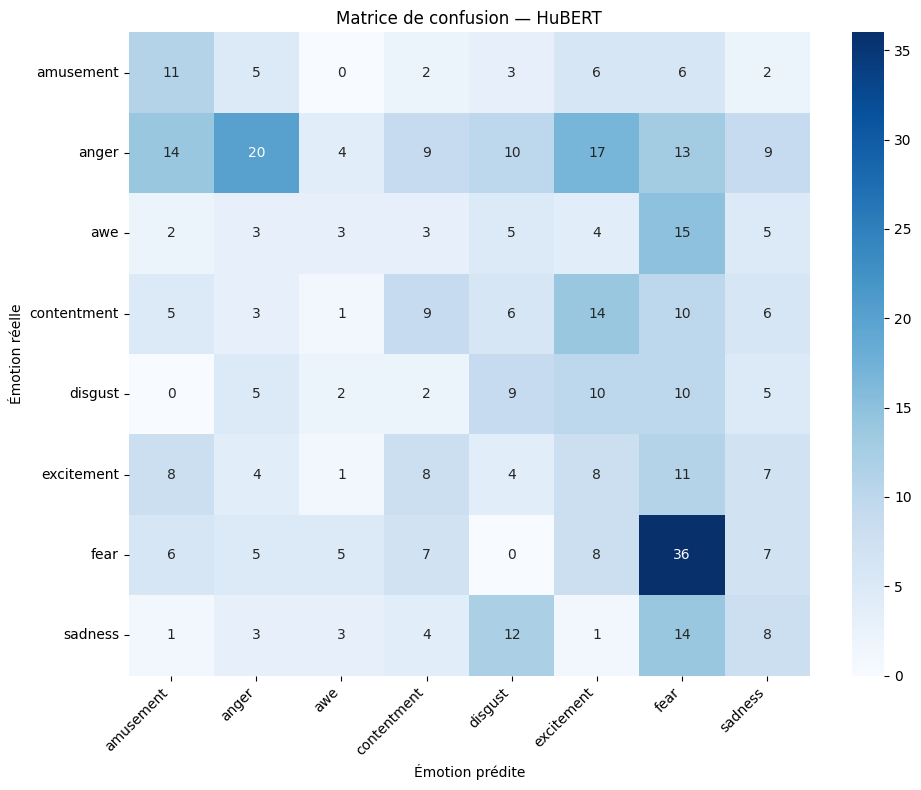

In [62]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Ordre des 8 émotions
labels_emotions = [
    "amusement", "anger", "awe", "contentment",
    "disgust", "excitement", "fear", "sadness"
]

# Calcul de la matrice de confusion
cm = confusion_matrix(
    y_test_hubert,
    y_pred_test_hubert,
    labels=labels_emotions
)

# Affichage de la matrice
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels_emotions,
    yticklabels=labels_emotions
)

plt.xlabel("Émotion prédite")
plt.ylabel("Émotion réelle")
plt.title("Matrice de confusion — HuBERT")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Analyse de la matrice de confusion — HuBERT

La matrice de confusion permet d'analyser les prédictions du modèle HuBERT sur les 439 extraits du jeu de test. Les lignes représentent les émotions réelles et les colonnes les émotions prédites. La diagonale correspond aux classifications correctes, tandis que les valeurs hors diagonale représentent les confusions entre émotions.

#### 1. Principales observations

- **Peur (*fear*) :** c'est l'émotion la mieux reconnue, avec 36 extraits correctement classés sur 74. Le modèle distingue relativement bien cette émotion des autres.
- **Colère (*anger*) :** 20 extraits sur 96 sont correctement classés. Les erreurs sont réparties entre plusieurs émotions, notamment l'amusement (14 extraits) et l'excitation (17 extraits).
- **Amusement (*amusement*) :** 0 extraits sur 35 sont correctement identifiés. Les erreurs concernent notamment la colère et l'excitation, avec 5 et 6 extraits respectivement.
- **Émerveillement (*awe*) :** seuls 3 extraits sur 40 sont correctement classés. Cette émotion est notamment confondue avec la peur (15 extraits).
- **Satisfaction (*contentment*) :** 9 extraits sur 54 sont correctement classés. Le modèle confond fréquemment cette émotion avec l'excitation (14 extraits) et la peur (10 extraits).
- **Dégoût (*disgust*) :** 9 extraits sur 43 sont correctement classés. Plusieurs extraits sont prédits comme excitation ou peur (10 extraits pour chacune).
- **Excitation (*excitement*) :** 8 extraits sur 51 sont correctement classés. La peur est la prédiction erronée la plus fréquente, avec 11 extraits.
- **Tristesse (*sadness*) :** 8 extraits sur 46 sont correctement classés. Elle est souvent confondue avec le dégoût (12 extraits) et la peur (14 extraits).

#### 2. Conclusion

La matrice de confusion confirme que les performances du modèle HuBERT varient selon les émotions. La peur est la classe la mieux reconnue, tandis que l'émerveillement présente les plus grandes difficultés de classification.

Les confusions entre plusieurs émotions montrent que les représentations audio utilisées ne permettent pas toujours de distinguer clairement les catégories émotionnelles. Le modèle obtient ainsi un F1-macro de 0,214 sur le jeu de test, ce qui souligne les limites de cette approche fondée sur une régression logistique appliquée aux embeddings audio.

**Évaluer wav2vec 2.0 base sur le jeu de test**

In [63]:
# Préparer les données wav2vec 2.0 base
X_train_wav2vec_final = X_wav2vec_moy[est_train]
X_test_wav2vec_final = X_wav2vec_moy[est_test]

y_train_wav2vec_final = y[est_train]
y_test_wav2vec_final = y[est_test]

# Standardisation : ajustement uniquement sur le train
scaler_wav2vec_final = StandardScaler()

X_train_wav2vec_final_scaled = scaler_wav2vec_final.fit_transform(
    X_train_wav2vec_final
)
X_test_wav2vec_final_scaled = scaler_wav2vec_final.transform(
    X_test_wav2vec_final
)

# Entraîner le modèle avec le meilleur C retenu
clf_wav2vec_final = LogisticRegression(
    C=0.00025,
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

clf_wav2vec_final.fit(
    X_train_wav2vec_final_scaled,
    y_train_wav2vec_final
)

# Prédictions sur le jeu de test
y_pred_test_wav2vec = clf_wav2vec_final.predict(
    X_test_wav2vec_final_scaled
)

# Calcul du F1-macro
f1_test_wav2vec = f1_score(
    y_test_wav2vec_final,
    y_pred_test_wav2vec,
    average="macro"
)

print("F1-macro wav2vec 2.0 base sur test :",
      round(f1_test_wav2vec, 3))

F1-macro wav2vec 2.0 base sur test : 0.196


### Évaluation de wav2vec 2.0 base sur le jeu de test

Le modèle wav2vec 2.0 base, utilisant la moyenne des représentations de ses 13 couches et une régression logistique avec `C = 0.00025`, obtient un **F1-macro de 0,196 sur le jeu de test**.

Ce résultat est inférieur à celui de HuBERT base, qui obtient un F1-macro de 0,214 sur le même jeu de test. Dans notre expérimentation, HuBERT base présente donc de meilleures performances globales pour la classification des huit émotions.

Le jeu de test étant réservé à l'évaluation finale, ces résultats ne seront pas utilisés pour ajuster les hyperparamètres.


**évaluer wav2vec2-superb-er**

In [64]:
scaler_emotion_final = StandardScaler()

X_train_emotion_scaled = scaler_emotion_final.fit_transform(
    X_emotion_moy[est_train]
)
X_test_emotion_scaled = scaler_emotion_final.transform(
    X_emotion_moy[est_test]
)

clf_emotion_final = LogisticRegression(
    C=0.003,
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

clf_emotion_final.fit(X_train_emotion_scaled, y[est_train])

y_pred_test_emotion = clf_emotion_final.predict(X_test_emotion_scaled)

f1_test_emotion = f1_score(
    y[est_test], y_pred_test_emotion, average="macro"
)

print("F1-macro wav2vec2-superb-er sur test :", round(f1_test_emotion, 3))

F1-macro wav2vec2-superb-er sur test : 0.262


In [65]:
import pandas as pd

resultats = pd.DataFrame({
    "Modèle": [
        "HuBERT base",
        "wav2vec 2.0 base",
        "wav2vec2-superb-er"
    ],
    "F1-macro validation": [0.274, 0.235, 0.251],
    "F1-macro test": [0.214, 0.196, 0.262]
})

display(resultats.sort_values("F1-macro test", ascending=False))

,Modèle,F1-macro validation,F1-macro test
2,wav2vec2-superb-er,0.251,0.262
0,HuBERT base,0.274,0.214
1,wav2vec 2.0 base,0.235,0.196


**exporter les probabilités de dev et de test pour les trois modèles**

In [66]:
import os, numpy as np, pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Dossier de sortie pour les prédictions (partagé avec le binôme)
DOSSIER_PREDS = f"{DRIVE}/preds"
os.makedirs(DOSSIER_PREDS, exist_ok=True)

# Configuration retenue pour chaque modèle : embeddings moyennés sur les 13 couches + meilleur C sur dev
configs = {
    "audio_hubert":   {"X": Xc,            "C": 0.0005},    # HuBERT base
    "audio_wav2vec2": {"X": X_wav2vec_moy, "C": 0.00025},   # wav2vec 2.0 base
    "audio_superber": {"X": X_emotion_moy, "C": 0.003},     # wav2vec2-superb-er
}

for nom, cfg in configs.items():
    X_moy = cfg["X"]

    # Standardisation : moyenne et écart-type calculés sur le TRAIN uniquement
    sc = StandardScaler().fit(X_moy[est_train])

    # Entraînement sur le train
    clf_export = LogisticRegression(C=cfg["C"], class_weight="balanced",
                                    max_iter=2000, random_state=42)
    clf_export.fit(sc.transform(X_moy[est_train]), y[est_train])

    # On exporte les clips de dev et de test (pas le train : ses prédictions sont trop optimistes)
    masque = est_dev | est_test
    proba = clf_export.predict_proba(sc.transform(X_moy[masque]))

    # Tableau : identifiants + vraie émotion + une colonne de probabilité par émotion
    # clf_export.classes_ est dans l'ordre alphabétique
    sortie = labels.loc[masque, ["video_id", "split", "emotion"]].reset_index(drop=True)
    sortie[list(clf_export.classes_)] = proba

    sortie.to_csv(f"{DOSSIER_PREDS}/{nom}.csv", index=False)
    print(nom, "->", sortie.shape, "| classes :", list(clf_export.classes_))

# Contrôle : les probabilités de chaque clip doivent sommer à 1
print("Somme des probabilités (première ligne) :",
      round(sortie[list(clf_export.classes_)].iloc[0].sum(), 3))

audio_hubert -> (881, 11) | classes : ['amusement', 'anger', 'awe', 'contentment', 'disgust', 'excitement', 'fear', 'sadness']
audio_wav2vec2 -> (881, 11) | classes : ['amusement', 'anger', 'awe', 'contentment', 'disgust', 'excitement', 'fear', 'sadness']
audio_superber -> (881, 11) | classes : ['amusement', 'anger', 'awe', 'contentment', 'disgust', 'excitement', 'fear', 'sadness']
Somme des probabilités (première ligne) : 1.0


**vérifier les fichiers exportés**

In [67]:
import os, pandas as pd, numpy as np
from sklearn.metrics import f1_score

DOSSIER_PREDS = f"{DRIVE}/preds"
emotions = ["amusement", "anger", "awe", "contentment",
            "disgust", "excitement", "fear", "sadness"]

for nom in ["audio_hubert", "audio_wav2vec2", "audio_superber"]:
    # Relire le fichier tel que les autres le liront
    p = pd.read_csv(f"{DOSSIER_PREDS}/{nom}.csv", dtype={"video_id": str})

    # 1. Colonnes d'émotions dans l'ordre alphabétique attendu
    print(f"\n{nom} : {p.shape} | ordre des colonnes correct :", list(p.columns[3:]) == emotions)

    # 2. Valeurs manquantes et clips en double
    print("Valeurs manquantes :", p.isna().any().any(), "| doublons :", p["video_id"].duplicated().any())

    # 3. Macro-F1 recalculée à partir du fichier, pour dev et test
    for s in ["dev", "test"]:
        sous = p[p["split"] == s]
        pred = sous[emotions].idxmax(axis=1)      # émotion de plus forte probabilité
        f1 = f1_score(sous["emotion"], pred, average="macro")
        print(f"  macro-F1 {s} : {f1:.3f} ({len(sous)} clips)")


audio_hubert : (881, 11) | ordre des colonnes correct : True
Valeurs manquantes : False | doublons : False
  macro-F1 dev : 0.274 (442 clips)
  macro-F1 test : 0.214 (439 clips)

audio_wav2vec2 : (881, 11) | ordre des colonnes correct : True
Valeurs manquantes : False | doublons : False
  macro-F1 dev : 0.235 (442 clips)
  macro-F1 test : 0.196 (439 clips)

audio_superber : (881, 11) | ordre des colonnes correct : True
Valeurs manquantes : False | doublons : False
  macro-F1 dev : 0.251 (442 clips)
  macro-F1 test : 0.262 (439 clips)


**mesurer l’incertitude sur le jeu de test avec un bootstrap**

In [68]:
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

emotions = [
    "amusement", "anger", "awe", "contentment",
    "disgust", "excitement", "fear", "sadness"
]

modeles = {
    "HuBERT base": "audio_hubert.csv",
    "wav2vec 2.0 base": "audio_wav2vec2.csv",
    "wav2vec2-superb-er": "audio_superber.csv"
}

rng = np.random.default_rng(42)
n_boot = 2000
resultats_bootstrap = []

for nom, fichier in modeles.items():
    df = pd.read_csv(
        f"{DOSSIER_PREDS}/{fichier}",
        dtype={"video_id": str}
    )

    # Garder uniquement le jeu de test
    df = df[df["split"] == "test"].copy()

    # Retrouver l'identifiant du film
    df["film_id"] = df["video_id"].str.split("_clip").str[0]

    # Prédiction = émotion ayant la probabilité la plus élevée
    y_reel = df["emotion"].to_numpy()
    y_pred = df[emotions].idxmax(axis=1).to_numpy()

    f1_observe = f1_score(
        y_reel, y_pred, labels=emotions,
        average="macro", zero_division=0
    )

    films = df["film_id"].unique()
    scores_boot = []

    # Bootstrap par film
    for _ in range(n_boot):
        films_tires = rng.choice(films, size=len(films), replace=True)

        echantillons = pd.concat(
            [df[df["film_id"] == film] for film in films_tires],
            ignore_index=True
        )

        pred_boot = echantillons[emotions].idxmax(axis=1)

        score = f1_score(
            echantillons["emotion"], pred_boot,
            labels=emotions, average="macro",
            zero_division=0
        )
        scores_boot.append(score)

    borne_inf, borne_sup = np.percentile(scores_boot, [2.5, 97.5])

    resultats_bootstrap.append({
        "Modèle": nom,
        "F1-macro test": round(f1_observe, 3),
        "IC 95 % inférieur": round(borne_inf, 3),
        "IC 95 % supérieur": round(borne_sup, 3)
    })

tableau_ic = pd.DataFrame(resultats_bootstrap)
display(tableau_ic)

,Modèle,F1-macro test,IC 95 % inférieur,IC 95 % supérieur
0,HuBERT base,0.214,0.161,0.254
1,wav2vec 2.0 base,0.196,0.153,0.229
2,wav2vec2-superb-er,0.262,0.212,0.306


**Comparaison appariée par bootstrap**

In [69]:
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

emotions = [
    "amusement", "anger", "awe", "contentment",
    "disgust", "excitement", "fear", "sadness"
]

modeles = {
    "HuBERT base": "audio_hubert.csv",
    "wav2vec 2.0 base": "audio_wav2vec2.csv",
    "wav2vec2-superb-er": "audio_superber.csv"
}

# Charger les prédictions du test
predictions = {}

for nom, fichier in modeles.items():
    df = pd.read_csv(
        f"{DOSSIER_PREDS}/{fichier}",
        dtype={"video_id": str}
    )
    df = df[df["split"] == "test"].copy()
    df["film_id"] = df["video_id"].str.split("_clip").str[0]
    df["prediction"] = df[emotions].idxmax(axis=1)
    predictions[nom] = df[
        ["video_id", "film_id", "emotion", "prediction"]
    ].rename(columns={"prediction": nom})

# Aligner les prédictions sur les mêmes extraits
comparaison = None

for nom, df in predictions.items():
    colonnes = ["video_id", "film_id", "emotion", nom]
    if comparaison is None:
        comparaison = df[colonnes].copy()
    else:
        comparaison = comparaison.merge(
            df[colonnes],
            on=["video_id", "film_id", "emotion"],
            how="inner",
            validate="one_to_one"
        )

# Bootstrap apparié par film
rng = np.random.default_rng(42)
films = comparaison["film_id"].unique()
n_boot = 2000

paires = [
    ("wav2vec2-superb-er", "HuBERT base"),
    ("wav2vec2-superb-er", "wav2vec 2.0 base"),
    ("HuBERT base", "wav2vec 2.0 base")
]

differences = {paire: [] for paire in paires}

for _ in range(n_boot):
    films_tires = rng.choice(films, size=len(films), replace=True)
    echantillon = pd.concat(
        [comparaison[comparaison["film_id"] == film]
         for film in films_tires],
        ignore_index=True
    )

    scores = {
        nom: f1_score(
            echantillon["emotion"],
            echantillon[nom],
            labels=emotions,
            average="macro",
            zero_division=0
        )
        for nom in modeles
    }

    for a, b in paires:
        differences[(a, b)].append(scores[a] - scores[b])

# Résumé des différences
lignes = []

for a, b in paires:
    diff_obs = (
        f1_score(comparaison["emotion"], comparaison[a],
                 labels=emotions, average="macro", zero_division=0)
        -
        f1_score(comparaison["emotion"], comparaison[b],
                 labels=emotions, average="macro", zero_division=0)
    )

    bas, haut = np.percentile(differences[(a, b)], [2.5, 97.5])

    lignes.append({
        "Comparaison": f"{a} − {b}",
        "Différence F1 observée": round(diff_obs, 3),
        "IC 95 % inférieur": round(bas, 3),
        "IC 95 % supérieur": round(haut, 3),
        "IC exclut zéro": bas > 0 or haut < 0
    })

display(pd.DataFrame(lignes))

,Comparaison,Différence F1 observée,IC 95 % inférieur,IC 95 % supérieur,IC exclut zéro
0,wav2vec2-superb-er − HuBERT base,0.048,0.011,0.085,True
1,wav2vec2-superb-er − wav2vec 2.0 base,0.065,0.020,0.109,True
2,HuBERT base − wav2vec 2.0 base,0.018,-0.019,0.050,False


### Comparaison des modèles et mesure de l'incertitude

Une comparaison appariée par bootstrap, avec rééchantillonnage des films, a été réalisée afin d’évaluer la robustesse des différences de F1-macro sur le jeu de test.

Le modèle **wav2vec2-superb-er** obtient un F1-macro de 0,262 et présente de meilleures performances que HuBERT base (différence de 0,048 ; IC à 95 % : [0,011 ; 0,085]) et wav2vec 2.0 base (différence de 0,065 ; IC à 95 % : [0,020 ; 0,109]). Les deux intervalles excluent zéro, ce qui indique que les écarts observés sont robustes au rééchantillonnage des films.

En revanche, la différence entre HuBERT base et wav2vec 2.0 base est de 0,018 (IC à 95 % : [-0,019 ; 0,050]). Cet intervalle contient zéro ; les données ne permettent donc pas d'établir clairement une différence entre ces deux modèles.

Dans cette expérimentation, wav2vec2-superb-er est le modèle le plus performant parmi les trois modèles audio évalués. Cette conclusion reste limitée au corpus, à la partition et aux configurations étudiées.


**retrouver les objets du modèle déjà entraîné dans la mémoire de Colab.**

In [70]:
# Retrouver le classifieur et le scaler déjà entraînés
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

print("Classifieurs disponibles :")
for nom, objet in globals().copy().items():
    if isinstance(objet, LogisticRegression):
        print(f"- {nom}")

print("\nScalers disponibles :")
for nom, objet in globals().copy().items():
    if isinstance(objet, StandardScaler):
        print(f"- {nom}")

Classifieurs disponibles :
- model
- clf
- clf_couche
- clf_comb
- clf_wav2vec
- clf_emotion
- clf_hubert
- clf_wav2vec_final
- clf_emotion_final
- clf_export

Scalers disponibles :
- sc
- scaler
- sc_couche
- sc_comb
- scaler_wav2vec
- scaler_emotion
- scaler_hubert
- scaler_wav2vec_final
- scaler_emotion_final


In [71]:
print("Classifieur :", clf_emotion_final)
print("Scaler :", scaler_emotion_final)
print("Forme des données d'entraînement :", clf_emotion_final.n_features_in_)
print("Nombre de classes :", len(clf_emotion_final.classes_))
print("Classes :", clf_emotion_final.classes_)

Classifieur : LogisticRegression(C=0.003, class_weight='balanced', max_iter=2000,
                   random_state=42)
Scaler : StandardScaler()
Forme des données d'entraînement : 768
Nombre de classes : 8
Classes : ['amusement' 'anger' 'awe' 'contentment' 'disgust' 'excitement' 'fear'
 'sadness']


**tester les prédictions sur le jeu de test**

In [72]:
import pandas as pd
import numpy as np

# Sélection des extraits du jeu de test
X_test_emotion = X_emotion_moy[est_test]
y_test_emotion = np.asarray(y)[est_test]

# Prédictions et probabilités
X_test_scaled = scaler_emotion_final.transform(X_test_emotion)
predictions = clf_emotion_final.predict(X_test_scaled)
probabilites = clf_emotion_final.predict_proba(X_test_scaled)

# Tableau de comparaison
resultats = pd.DataFrame({
    "Emotion réelle": y_test_emotion,
    "Emotion prédite": predictions,
    "Probabilité max (%)": np.round(probabilites.max(axis=1) * 100, 1),
    "Correct ?": y_test_emotion == predictions
})

display(resultats.head(10))

,Emotion réelle,Emotion prédite,Probabilité max (%),Correct ?
0,anger,anger,32.3,True
1,anger,anger,27.7,True
2,contentment,disgust,23.7,False
3,anger,anger,26.7,True
4,anger,anger,28.3,True
5,anger,anger,25.8,True
6,anger,anger,25.0,True
7,fear,disgust,28.3,False
8,excitement,excitement,20.9,True
9,disgust,disgust,27.7,True


Interprétation des 10 extraits affichés
- 8 prédictions correctes sur 10, soit 80 % sur cet aperçu.
- Les deux erreurs visibles :
  - contentment prédit comme disgust.
  - fear prédit comme disgust.
- Les probabilités maximales sont plutôt faibles, entre 20,9 % et 32,3 % : le modèle hésite entre plusieurs émotions.

**afficher un bilan complet**

In [73]:
from sklearn.metrics import accuracy_score, classification_report, f1_score

print("Accuracy :", round(accuracy_score(y_test_emotion, predictions), 3))
print("F1-macro :", round(f1_score(
    y_test_emotion, predictions, average="macro"
), 3))

print("\nRapport par émotion :")
print(classification_report(
    y_test_emotion,
    predictions,
    labels=clf_emotion_final.classes_,
    zero_division=0
))

Accuracy : 0.273
F1-macro : 0.262

Rapport par émotion :
              precision    recall  f1-score   support

   amusement       0.33      0.54      0.41        35
       anger       0.48      0.25      0.33        96
         awe       0.23      0.12      0.16        40
 contentment       0.23      0.26      0.24        54
     disgust       0.16      0.19      0.17        43
  excitement       0.20      0.25      0.22        51
        fear       0.33      0.36      0.35        74
     sadness       0.19      0.22      0.20        46

    accuracy                           0.27       439
   macro avg       0.27      0.28      0.26       439
weighted avg       0.30      0.27      0.27       439



**résultat global et de voir quelles émotions le modèle reconnaît le mieux, sans réentraîner quoi que ce soit.**

Amusement : 0,41 — c’est l’émotion la mieux reconnue.
Peur : 0,35 — deuxième meilleure performance.
Colère : 0,33 — précision assez bonne (0,48), mais rappel faible (0,25) : le modèle manque beaucoup d’extraits de colère.
Émerveillement : 0,16 et dégoût : 0,17 — les émotions les plus difficiles à reconnaître.

**Conclusion**
Le modèle wav2vec2-superb-er reste le meilleur des trois modèles audio selon les résultats de test obtenus, avec un F1-macro de 0,262. Cependant, il ne reconnaît pas toutes les émotions avec la même efficacité.

Ce test confirme donc qu’il est pertinent de le retenir comme modèle audio candidat pour la fusion multimodale, sans prétendre qu’il est très performant en classification individuelle.

**examiner les prédictions d’un modèle sur le test**

In [74]:
import numpy as np, pandas as pd
from sklearn.metrics import classification_report, accuracy_score

# Modèle à examiner : changer ce nom pour comparer
# ("audio_hubert", "audio_wav2vec2" ou "audio_superber")
NOM = "audio_superber"

emotions = ["amusement", "anger", "awe", "contentment",
            "disgust", "excitement", "fear", "sadness"]

# Charger les prédictions exportées, et garder uniquement le test
p = pd.read_csv(f"{DRIVE}/preds/{NOM}.csv", dtype={"video_id": str})
p = p[p["split"] == "test"].reset_index(drop=True)

# Émotion prédite = celle de plus forte probabilité ; confiance = cette probabilité
p["prediction"] = p[emotions].idxmax(axis=1)
p["confiance"] = p[emotions].max(axis=1).round(2)

# 1. Résultats globaux et par émotion
print(NOM, "- accuracy :", round(accuracy_score(p["emotion"], p["prediction"]), 3))
print(classification_report(p["emotion"], p["prediction"], zero_division=0))

# 2. 12 clips tirés au hasard : réel, prédit, confiance
exemples = p.sample(12, random_state=1)[["video_id", "emotion", "prediction", "confiance"]]
exemples["ok"] = np.where(exemples["emotion"] == exemples["prediction"], "oui", "non")
print(exemples.to_string(index=False))

# 3. Écouter les clips (utilise la copie locale des WAV)
from IPython.display import Audio, display
for vid in exemples["video_id"].head(4):
    print(vid)
    display(Audio(f"/content/wav16k/{vid}.wav"))

audio_superber - accuracy : 0.273
              precision    recall  f1-score   support

   amusement       0.33      0.54      0.41        35
       anger       0.48      0.25      0.33        96
         awe       0.23      0.12      0.16        40
 contentment       0.23      0.26      0.24        54
     disgust       0.16      0.19      0.17        43
  excitement       0.20      0.25      0.22        51
        fear       0.33      0.36      0.35        74
     sadness       0.19      0.22      0.20        46

    accuracy                           0.27       439
   macro avg       0.27      0.28      0.26       439
weighted avg       0.30      0.27      0.27       439

      video_id     emotion prediction  confiance  ok
00308_clip_008  excitement excitement       0.24 oui
00157_clip_023     sadness      anger       0.24 non
00081_clip_065       anger       fear       0.46 non
00186_clip_014       anger    sadness       0.37 non
00370_clip_002         awe  amusement       0.22 n

00157_clip_023


00081_clip_065


00186_clip_014


J’ai choisi de ne pas effectuer de fine-tuning, notamment parce que je ne disposais pas d’un GPU adapté pour réaliser cette étape dans de bonnes conditions. Le fine-tuning de modèles audio pré-entraînés demande davantage de ressources de calcul et du temps pour entraîner les modèles et ajuster les hyperparamètres.

J’ai donc privilégié une approche plus légère : extraire les représentations audio de trois modèles pré-entraînés, puis entraîner des classifieurs par régression logistique. Cela m’a permis de comparer les trois modèles sur les mêmes jeux de validation et de test, tout en produisant les probabilités nécessaires à la fusion multimodale.

Le fine-tuning reste une piste d’amélioration que je pourrais explorer avec des ressources de calcul adaptées, afin de vérifier s’il permet réellement d’améliorer les performances.

**exportation des prédictions**

In [75]:
import os

print("Drive monté :", os.path.exists("/content/drive/MyDrive"))
print("Dossier du projet :", os.path.exists("/content/data/PROJET_SID_2026/movie"))

Drive monté : True
Dossier du projet : True


In [76]:

# Exporter les probabilités audio pour préparer la fusion

import os
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

DOSSIER_PREDS = f"{DRIVE}/preds"
os.makedirs(DOSSIER_PREDS, exist_ok=True)

# Modèles audio retenus et paramètres sélectionnés sur dev
configs = {
    "audio_hubert": {
        "X": Xc,
        "C": 0.0005
    },
    "audio_wav2vec2": {
        "X": X_wav2vec_moy,
        "C": 0.00025
    },
    "audio_superber": {
        "X": X_emotion_moy,
        "C": 0.003
    }
}

# Vérifier que le masque test existe
est_test = (labels["split"] == "test").values

for nom, cfg in configs.items():
    X_modele = cfg["X"]

    # Standardisation calculée uniquement sur train
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_modele[est_train])

    # Entraînement sur train
    clf = LogisticRegression(
        C=cfg["C"],
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    )
    clf.fit(X_train_scaled, y[est_train])

    # Probabilités pour dev et test
    masque = est_dev | est_test
    X_eval_scaled = scaler.transform(X_modele[masque])
    probabilites = clf.predict_proba(X_eval_scaled)

    # Créer le fichier avec les identifiants et les probabilités
    sortie = labels.loc[
        masque, ["video_id", "split", "emotion"]
    ].reset_index(drop=True)

    for j, classe in enumerate(clf.classes_):
        sortie[classe] = probabilites[:, j]

    chemin = f"{DOSSIER_PREDS}/{nom}.csv"
    sortie.to_csv(chemin, index=False)

    print(f"{nom} : exporté vers {chemin}")
    print("Dimensions :", sortie.shape)
    print("Somme des probabilités :",
          np.round(probabilites[0].sum(), 3))

print("\nExport terminé.")


audio_hubert : exporté vers /content/drive/MyDrive/projet_emovid/preds/audio_hubert.csv
Dimensions : (881, 11)
Somme des probabilités : 1.0
audio_wav2vec2 : exporté vers /content/drive/MyDrive/projet_emovid/preds/audio_wav2vec2.csv
Dimensions : (881, 11)
Somme des probabilités : 1.0
audio_superber : exporté vers /content/drive/MyDrive/projet_emovid/preds/audio_superber.csv
Dimensions : (881, 11)
Somme des probabilités : 1.0

Export terminé.


881 lignes par fichier : 442 extraits dev + 439 extraits test.
11 colonnes : identifiant vidéo, split, émotion réelle et 8 probabilités d’émotion.
La somme des probabilités vaut 1.0 : c’est cohérent avec une distribution de probabilités pour un extrait.

**Vérifier les embeddings déjà exportés**

In [77]:

# Vérification des embeddings sauvegardés sur Google Drive

import os
import numpy as np

DOSSIER_EMB = f"{DRIVE}/embeddings"

fichiers = [
    "hubert_base.npy",
    "wav2vec2_base.npy",
    "wav2vec2_emotion.npy"
]

for fichier in fichiers:
    chemin = os.path.join(DOSSIER_EMB, fichier)

    if os.path.exists(chemin):
        X_emb = np.load(chemin, mmap_mode="r")
        print(f"{fichier} : {X_emb.shape}")
    else:
        print(f"{fichier} : fichier introuvable")

print("\nVérification terminée.")


hubert_base.npy : (3088, 13, 768)
wav2vec2_base.npy : (3088, 13, 768)
wav2vec2_emotion.npy : (3088, 13, 768)

Vérification terminée.


**chargement des embeddings de l’audio avec parole et ceux de l’audio sans parole (ast.npz), puis affiche leurs dimensions pour préparer la fusion précoce**

**embedding pour représenter l’audio avec parole**

In [90]:
import numpy as np

DOSSIER = "/content/drive/MyDrive/projet_emovid/embeddings"

X_parole = np.load(f"{DOSSIER}/wav2vec2_emotion.npy")

# Moyenne des représentations des 13 couches
X_parole = X_parole.mean(axis=1)

print(X_parole.shape)  # (3088, 768)

(3088, 768)


**Localiser le fichier ast.npz**

In [89]:
import os

for racine, dossiers, fichiers in os.walk("/content/drive/MyDrive"):
    for fichier in fichiers:
        if fichier.lower().endswith(".npz") and "ast" in fichier.lower():
            print(os.path.join(racine, fichier))

/content/drive/MyDrive/projet_emovid/embeddings/Copie de Copie de Copie de ast.npz
/content/drive/MyDrive/projet_emovid/embeddings/Copie de Copie de ast.npz


In [88]:
import os, numpy as np

# Adapter ce chemin à l'endroit où se trouve le fichier de ton binôme
chemin = f"{DRIVE}/ast.npz"
print("Fichier trouvé :", os.path.exists(chemin))

if os.path.exists(chemin):
    # allow_pickle=True est nécessaire seulement si le fichier contient des listes de texte
    donnees = np.load(chemin, allow_pickle=True)

    # Lister tous les tableaux contenus dans le fichier, avec leur forme
    for nom in donnees.files:
        print(nom, "->", donnees[nom].shape)

    # Si le fichier contient une liste d'identifiants de clips, afficher les premiers
    for nom in donnees.files:
        if "id" in nom.lower():
            print("Premiers identifiants :", donnees[nom][:3])
else:
    # Aider à retrouver le fichier : lister le contenu du dossier du projet
    print(os.listdir(DRIVE))

Fichier trouvé : False
['Group 1.csv', 'wav16k', 'embeddings', 'Group_1.csv', 'preds', 'labels.csv', 'courbe_couches.png', 'Copie de Copie de audio_wav2vec2.csv', 'Copie de Copie de audio_hubert.csv', 'Copie de Copie de ast_test.csv', 'Copie de Copie de audio_superber.csv', 'Copie de Copie de ast_dev.csv']


In [81]:
import pandas as pd

# Les fichiers ont gardé le préfixe "Copie de Copie de " dans leur nom
for nom in ["Copie de Copie de ast_dev.csv", "Copie de Copie de ast_test.csv"]:
    p = pd.read_csv(f"{DRIVE}/{nom}", dtype=str)   # dtype=str : garder les zéros des identifiants
    print("=====", nom)
    print("Forme :", p.shape)
    print("Colonnes :", list(p.columns))
    print(p.head(3).to_string())
    print()

===== Copie de Copie de ast_dev.csv
Forme : (442, 9)
Colonnes : ['video_id', 'amusement', 'awe', 'contentment', 'excitement', 'anger', 'disgust', 'fear', 'sadness']
         video_id amusement       awe contentment excitement     anger   disgust      fear   sadness
0  00008_clip_001  0.190428  0.085668    0.060611   0.124309  0.129875  0.064068  0.264097  0.080944
1  00008_clip_002  0.055373  0.099960    0.056046   0.071914  0.113366  0.054876  0.386544  0.161921
2  00008_clip_006  0.076556  0.102812    0.076551   0.090232  0.150175  0.071876  0.314246  0.117551

===== Copie de Copie de ast_test.csv
Forme : (439, 9)
Colonnes : ['video_id', 'amusement', 'awe', 'contentment', 'excitement', 'anger', 'disgust', 'fear', 'sadness']
         video_id amusement       awe contentment excitement     anger   disgust      fear   sadness
0  00000_clip_001  0.146267  0.121643    0.129817   0.154654  0.148003  0.146872  0.079277  0.073468
1  00000_clip_002  0.106951  0.103821    0.108485   0.149622  

**fusionner HuBERT et AST avec un poids réglé sur dev**

In [85]:
import pandas as pd, numpy as np
from sklearn.metrics import f1_score

emotions = ["amusement", "anger", "awe", "contentment",
            "disgust", "excitement", "fear", "sadness"]

# Modèle audio retenu (choisi sur dev) : changer ici si le groupe en retient un autre
MON_MODELE = "audio_hubert"

# 1. Mes prédictions (déjà en ordre alphabétique)
mien = pd.read_csv(f"{DRIVE}/preds/{MON_MODELE}.csv", dtype={"video_id": str}).set_index("video_id").sort_index()

# 2. Prédictions d'AST (dev et test séparés), colonnes remises PAR NOM dans le même ordre
ast_dev = pd.read_csv(f"{DRIVE}/Copie de Copie de ast_dev.csv", dtype={"video_id": str})
ast_test = pd.read_csv(f"{DRIVE}/Copie de Copie de ast_test.csv", dtype={"video_id": str})
ast = pd.concat([ast_dev, ast_test]).set_index("video_id").sort_index()[emotions]

# 3. Contrôle : mêmes clips, dans le même ordre
assert (mien.index == ast.index).all(), "Les clips des deux fichiers sont différents"
print("Alignement OK :", len(mien), "clips")

# 4. Émotion réelle et masques dev / test
y_vrai = mien["emotion"]
dev, test = (mien["split"] == "dev").values, (mien["split"] == "test").values
P_mien, P_ast = mien[emotions].values, ast.values

def macro_f1(proba, masque):
    pred = np.array(emotions)[proba[masque].argmax(axis=1)]
    return f1_score(y_vrai[masque], pred, average="macro")

# 5. Tester plusieurs poids sur DEV : w = poids de mon modèle, (1 - w) = poids d'AST
poids = np.round(np.arange(0, 1.01, 0.1), 1)
scores_dev = [macro_f1(w * P_mien + (1 - w) * P_ast, dev) for w in poids]
print("\nPoids de mon modèle -> macro-F1 dev")
for w, s in zip(poids, scores_dev):
    print(f"  {w:.1f} -> {s:.3f}")

# 6. Meilleur poids choisi sur dev
w_best = poids[int(np.argmax(scores_dev))]
print("\nMeilleur poids sur dev :", w_best)

# 7. Résultats finaux : chaque modèle seul, moyenne simple et fusion pondérée
P_fus = w_best * P_mien + (1 - w_best) * P_ast
P_moy = 0.5 * P_mien + 0.5 * P_ast
resume = pd.DataFrame({
    "modele": [MON_MODELE, "AST", "moyenne 50/50", f"pondérée (w={w_best})"],
    "F1 dev": [round(macro_f1(P, dev), 3) for P in (P_mien, P_ast, P_moy, P_fus)],
    "F1 test": [round(macro_f1(P, test), 3) for P in (P_mien, P_ast, P_moy, P_fus)],
})
print("\n", resume.to_string(index=False))

Alignement OK : 881 clips

Poids de mon modèle -> macro-F1 dev
  0.0 -> 0.236
  0.1 -> 0.243
  0.2 -> 0.247
  0.3 -> 0.259
  0.4 -> 0.263
  0.5 -> 0.249
  0.6 -> 0.253
  0.7 -> 0.249
  0.8 -> 0.256
  0.9 -> 0.263
  1.0 -> 0.274

Meilleur poids sur dev : 1.0

           modele  F1 dev  F1 test
    audio_hubert   0.274    0.214
             AST   0.236    0.248
   moyenne 50/50   0.249    0.217
pondérée (w=1.0)   0.274    0.214


La fusion testée ne montre donc pas de gain convaincant. AST semble apporter une information complémentaire intéressante, mais la moyenne des probabilités ne l’exploite pas efficacement dans cette expérience.

**Vérifions maintenant l’alignement exact**

In [92]:
import pandas as pd
import os

# Charger les prédictions audio et AST
audio = pd.read_csv(
    f"{DRIVE}/preds/audio_hubert.csv",
    dtype={"video_id": str}
)

ast_dev = pd.read_csv(
    f"{DRIVE}/Copie de Copie de ast_dev.csv",
    dtype={"video_id": str}
)

# Vérifier les identifiants
ids_audio = set(audio["video_id"])
ids_ast = set(ast_dev["video_id"])

# Alignement des clips présents dans les deux fichiers
comparaison = audio.merge(
    ast_dev,
    on="video_id",
    how="inner",
    suffixes=("_audio", "_ast"),
    validate="one_to_one"
)

print("Clips alignés :", len(comparaison))
print("Doublons audio :", audio["video_id"].duplicated().sum())
print("Doublons AST :", ast_dev["video_id"].duplicated().sum())
print("Clips absents de l'AST :", len(ids_audio - ids_ast))
print("Clips absents de l'audio :", len(ids_ast - ids_audio))
print("Émotion réelle disponible :", "emotion_audio" in comparaison.columns)
print("\nRépartition des clips alignés :")
print(comparaison["split"].value_counts())

Clips alignés : 442
Doublons audio : 0
Doublons AST : 0
Clips absents de l'AST : 439
Clips absents de l'audio : 0
Émotion réelle disponible : False

Répartition des clips alignés :
split
dev    442
Name: count, dtype: int64


**fusion des audios cad combinaison des prédictions de deux modèles audio — HuBERT et AST — puis à trouver la meilleure combinaison sur les 442 clips du jeu de développement (dev).**

In [93]:
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

# 1. Fusionner uniquement les clips dev
dev = audio[audio["split"] == "dev"].merge(
    ast_dev,
    on="video_id",
    how="inner",
    suffixes=("_audio", "_ast"),
    validate="one_to_one"
)

print("Nombre de clips dev fusionnés :", len(dev))
assert len(dev) == 442, "Vérifie les identifiants des clips dev."

# 2. Récupérer les probabilités des 8 émotions
emotions = [
    "amusement", "anger", "awe", "contentment",
    "disgust", "excitement", "fear", "sadness"
]

P_audio = dev[[f"{e}_audio" for e in emotions]].to_numpy()
P_ast = dev[[f"{e}_ast" for e in emotions]].to_numpy()
y_true = dev["emotion"].to_numpy()

# 3. Comparer audio seul, AST seul et fusion
def evaluer(probas):
    predictions = np.array(emotions)[probas.argmax(axis=1)]
    return f1_score(
        y_true, predictions,
        labels=emotions,
        average="macro",
        zero_division=0
    )

print(f"Audio seul : {evaluer(P_audio):.3f}")
print(f"AST seul   : {evaluer(P_ast):.3f}")

# 4. Rechercher le meilleur poids sur dev
resultats = []

for w in np.arange(0, 1.01, 0.05):
    P_fusion = w * P_audio + (1 - w) * P_ast
    resultats.append({
        "poids_audio": round(w, 2),
        "poids_AST": round(1 - w, 2),
        "F1_macro_dev": evaluer(P_fusion)
    })

resultats = pd.DataFrame(resultats).sort_values(
    "F1_macro_dev", ascending=False
)

display(resultats.head(10))

Nombre de clips dev fusionnés : 442
Audio seul : 0.274
AST seul   : 0.236


,poids_audio,poids_AST,F1_macro_dev
20,1.00,0.00,0.273851
19,0.95,0.05,0.273117
7,0.35,0.65,0.268424
18,0.90,0.10,0.263413
8,0.40,0.60,0.262580
6,0.30,0.70,0.258935
17,0.85,0.15,0.255837
16,0.80,0.20,0.255823
15,0.75,0.25,0.253728
5,0.25,0.75,0.253473


**fusion tardive des deux sources audio sur dev uniquement. Elle fusionne les probabilités du modèle audio avec parole et celles du modèle AST (audio sans parole), puis compare les résultats.**

In [94]:
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

# Charger les prédictions audio avec parole
audio = pd.read_csv(
    "/content/drive/MyDrive/projet_emovid/preds/audio_hubert.csv"
)

# Garder uniquement les clips de validation
audio_dev = audio[audio["split"] == "dev"].copy()

# ast_dev existe déjà dans ton notebook
# Fusionner les deux sources à partir de video_id
dev = audio_dev.merge(
    ast_dev,
    on="video_id",
    how="inner",
    suffixes=("_audio", "_ast"),
    validate="one_to_one"
)

print("Nombre de clips fusionnés :", len(dev))
assert len(dev) == 442, "Vérifie les identifiants des clips."

# Les 8 émotions
emotions = [
    "amusement", "anger", "awe", "contentment",
    "disgust", "excitement", "fear", "sadness"
]

# Extraire les probabilités des deux modèles
P_audio = dev[[f"{e}_audio" for e in emotions]].to_numpy()
P_ast = dev[[f"{e}_ast" for e in emotions]].to_numpy()

# Émotions réelles
y_true = dev["emotion"].to_numpy()

# Fonction d'évaluation : F1-score macro
def evaluer(probas):
    y_pred = np.array(emotions)[np.argmax(probas, axis=1)]
    return f1_score(
        y_true,
        y_pred,
        labels=emotions,
        average="macro",
        zero_division=0
    )

# Évaluer chaque source séparément
print(f"Audio avec parole : {evaluer(P_audio):.4f}")
print(f"Audio sans parole : {evaluer(P_ast):.4f}")

# Fusion tardive : moyenne des probabilités
P_fusion = (P_audio + P_ast) / 2

print(f"Fusion audio       : {evaluer(P_fusion):.4f}")

# Enregistrer les prédictions fusionnées
resultat = pd.DataFrame(P_fusion, columns=emotions)
resultat.insert(0, "video_id", dev["video_id"].to_numpy())
resultat["emotion"] = y_true

chemin = (
    "/content/drive/MyDrive/projet_emovid/"
    "preds/audio_fusion_dev.csv"
)

resultat.to_csv(chemin, index=False)
print("Fichier enregistré :", chemin)

Nombre de clips fusionnés : 442
Audio avec parole : 0.2739
Audio sans parole : 0.2363
Fusion audio       : 0.2487
Fichier enregistré : /content/drive/MyDrive/projet_emovid/preds/audio_fusion_dev.csv


**fusion pondérée sur Dev, en faisant varier le poids de chaque modèle. Cela permettra de vérifier si AST apporte une information complémentaire lorsqu’on lui attribue un poids plus faible.**


P_{fusion}=alpha P_{HuBERT}+(1-alpha)P_{AST}


In [95]:

import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

# Tester différents poids sur le jeu Dev
alphas = np.arange(0, 1.01, 0.05)
resultats = []

for alpha in alphas:
    P_fusion = alpha * P_audio + (1 - alpha) * P_ast

    y_pred = np.array(emotions)[np.argmax(P_fusion, axis=1)]

    f1 = f1_score(
        y_true,
        y_pred,
        labels=emotions,
        average="macro",
        zero_division=0
    )

    resultats.append({
        "alpha_HuBERT": round(alpha, 2),
        "poids_AST": round(1 - alpha, 2),
        "F1_macro": f1
    })

resultats_df = pd.DataFrame(resultats)
resultats_df = resultats_df.sort_values(
    "F1_macro", ascending=False
).reset_index(drop=True)

print("Classement des fusions pondérées sur Dev :")
display(resultats_df)

meilleur = resultats_df.iloc[0]

print("\nMeilleure fusion sur Dev :")
print(f"Poids HuBERT : {meilleur['alpha_HuBERT']:.2f}")
print(f"Poids AST    : {meilleur['poids_AST']:.2f}")
print(f"F1-macro     : {meilleur['F1_macro']:.4f}")


Classement des fusions pondérées sur Dev :


,alpha_HuBERT,poids_AST,F1_macro
0,1.00,0.00,0.273851
1,0.95,0.05,0.273117
2,0.35,0.65,0.268424
3,0.90,0.10,0.263413
4,0.40,0.60,0.262580
5,0.30,0.70,0.258935
6,0.85,0.15,0.255837
7,0.80,0.20,0.255823
8,0.75,0.25,0.253728
9,0.25,0.75,0.253473



Meilleure fusion sur Dev :
Poids HuBERT : 1.00
Poids AST    : 0.00
F1-macro     : 0.2739



### Bilan de la fusion pondérée

Les résultats montrent que la fusion pondérée n'améliore pas les performances de HuBERT sur le jeu de validation Dev.

| Modèle | F1-macro sur Dev |
|:--|--:|
| HuBERT seul | 0,2739 |
| Fusion pondérée optimale (\(\alpha = 1\)) | 0,2739 |
| Fusion simple (50/50) | 0,2488 |
| AST seul | 0,2363 |

Le meilleur poids obtenu est \(\alpha = 1\), soit :

\[
P_{\text{fusion}} = 1 \times P_{\text{HuBERT}} + 0 \times P_{\text{AST}}
\]
La fusion pondérée revient donc à utiliser HuBERT seul. L'ajout des prédictions AST n'améliore pas le F1-macro sur Dev pour les pondérations testées.

**Conclusion :** HuBERT est retenu comme modèle de référence. Les performances sur le jeu Test devront ensuite être évaluées sans utiliser ce jeu pour choisir les poids.


In [96]:

# Sauvegarder les prédictions de la meilleure fusion sur Dev

alpha_optimal = float(meilleur["alpha_HuBERT"])

P_fusion_dev = alpha_optimal * P_audio + (1 - alpha_optimal) * P_ast

predictions_dev = pd.DataFrame({
    "video_id": audio_dev["video_id"].to_numpy(),
    "emotion_reelle": y_true,
    "emotion_predite": np.array(emotions)[
        np.argmax(P_fusion_dev, axis=1)
    ]
})

# Ajouter les probabilités prédites pour chaque émotion
for i, emotion in enumerate(emotions):
    predictions_dev[f"proba_{emotion}"] = P_fusion_dev[:, i]

chemin_sortie = (
    "/content/drive/MyDrive/projet_emovid/preds/"
    "audio_fusion_ponderee_dev.csv"
)

predictions_dev.to_csv(chemin_sortie, index=False)

print("Fichier enregistré :", chemin_sortie)
print("Nombre de clips :", len(predictions_dev))
print("Poids HuBERT :", alpha_optimal)
print("Poids AST :", 1 - alpha_optimal)


Fichier enregistré : /content/drive/MyDrive/projet_emovid/preds/audio_fusion_ponderee_dev.csv
Nombre de clips : 442
Poids HuBERT : 1.0
Poids AST : 0.0


**fusion precode (embedding)**

In [97]:

import os

from google.colab import drive
drive.mount('/content/drive')

racine = "/content/drive/MyDrive"

for dossier, sous_dossiers, fichiers in os.walk(racine):
    for nom in fichiers:
        if nom in ["ast.npz", "hubert_base.npy", "ids.txt"]:
            print(os.path.join(dossier, nom))



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/projet_emovid/embeddings/hubert_base.npy
/content/drive/MyDrive/projet_emovid/embeddings/ids.txt


In [98]:
import os

for dossier, _, fichiers in os.walk("/content/drive/MyDrive"):
    for nom in fichiers:
        if nom.lower() == "ast.npz":
            print(os.path.join(dossier, nom))

In [99]:
import os
import numpy as np

dossier = "/content/drive/MyDrive/projet_emovid/embeddings"

# Vérifier les fichiers présents dans le répertoire
print("Fichiers du répertoire :")
for fichier in os.listdir(dossier):
    if "ast" in fichier.lower() or "hubert" in fichier.lower() or "ids" in fichier.lower():
        print(fichier)

# Charger les embeddings HuBERT
chemin_hubert = os.path.join(dossier, "hubert_base.npy")
hubert = np.load(chemin_hubert, mmap_mode="r")
print("\nForme des embeddings HuBERT :", hubert.shape)

# Rechercher les fichiers AST dans tout Google Drive
for racine, _, fichiers in os.walk("/content/drive/MyDrive"):
    for fichier in fichiers:
        if fichier.lower().endswith(".npz") and "ast" in fichier.lower():
            chemin = os.path.join(racine, fichier)
            print("\nFichier AST :", chemin)

            ast = np.load(chemin, allow_pickle=False)
            for cle in ast.files:
                print(f"  {cle} : {ast[cle].shape}, type : {ast[cle].dtype}")

Fichiers du répertoire :
hubert_base.npy
ids.txt
Copie de Copie de Copie de ast.npz
Copie de Copie de ast.npz
Copie de Copie de ids.txt
Copie de Copie de hubert_base.npy

Forme des embeddings HuBERT : (3088, 13, 768)

Fichier AST : /content/drive/MyDrive/projet_emovid/embeddings/Copie de Copie de Copie de ast.npz
  ids : (3088,), type : <U14
  X : (3088, 1295), type : float32

Fichier AST : /content/drive/MyDrive/projet_emovid/embeddings/Copie de Copie de ast.npz
  ids : (3088,), type : <U14
  X : (3088, 1295), type : float32


**Vérifier les identifiants et préparer les embeddings**

In [100]:

import os
import numpy as np

dossier = "/content/drive/MyDrive/projet_emovid/embeddings"

# Charger les embeddings HuBERT et les identifiants
hubert = np.load(os.path.join(dossier, "hubert_base.npy"))
ids_hubert = np.loadtxt(
    os.path.join(dossier, "ids.txt"),
    dtype=str
)

# Charger les embeddings AST
chemin_ast = os.path.join(
    dossier, "Copie de Copie de Copie de ast.npz"
)

ast_data = np.load(chemin_ast)
X_ast = ast_data["X"]
ids_ast = ast_data["ids"]

print("HuBERT :", hubert.shape)
print("IDs HuBERT :", ids_hubert.shape)
print("AST :", X_ast.shape)
print("IDs AST :", ids_ast.shape)

# Vérifier les identifiants
print("\nIDs HuBERT identiques aux IDs AST :",
      np.array_equal(ids_hubert, ids_ast))

# Résumer les 13 positions temporelles de HuBERT
X_hubert = hubert.mean(axis=1)

print("\nHuBERT après moyenne temporelle :", X_hubert.shape)

# Concaténer uniquement si les identifiants sont alignés
if np.array_equal(ids_hubert, ids_ast):
    X_audio_fusion = np.concatenate(
        [X_hubert, X_ast],
        axis=1
    )
    ids_audio_fusion = ids_hubert.copy()

    print("Embeddings fusionnés :", X_audio_fusion.shape)
else:
    print(
        "Attention : les identifiants diffèrent. "
        "Il faut aligner les lignes par ID avant la fusion."
    )


HuBERT : (3088, 13, 768)
IDs HuBERT : (3088,)
AST : (3088, 1295)
IDs AST : (3088,)

IDs HuBERT identiques aux IDs AST : True

HuBERT après moyenne temporelle : (3088, 768)
Embeddings fusionnés : (3088, 2063)


In [101]:

import os
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

base = "/content/drive/MyDrive/projet_emovid"
emb_dir = os.path.join(base, "embeddings")

# Charger les embeddings
hubert = np.load(os.path.join(emb_dir, "hubert_base.npy"))
hubert = hubert.mean(axis=1)

ast_data = np.load(
    os.path.join(emb_dir, "Copie de Copie de Copie de ast.npz")
)
X_ast = ast_data["X"]
ids_hubert = np.loadtxt(os.path.join(emb_dir, "ids.txt"), dtype=str)
ids_ast = ast_data["ids"]

assert np.array_equal(ids_hubert, ids_ast), "IDs non alignés"

X = np.concatenate([hubert, X_ast], axis=1)
ids = ids_hubert

# Examiner les labels et les partitions
labels = pd.read_csv(os.path.join(base, "labels.csv"))
print("Colonnes de labels.csv :", labels.columns.tolist())
display(labels.head())


Colonnes de labels.csv : ['video_id', 'emotion', 'film_id', 'split']


,video_id,emotion,film_id,split
0,00000_clip_001,anger,0,test
1,00000_clip_002,anger,0,test
2,00000_clip_006,contentment,0,test
3,00000_clip_009,anger,0,test
4,00000_clip_012,anger,0,test


In [102]:

import os
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

base = "/content/drive/MyDrive/projet_emovid"
emb_dir = os.path.join(base, "embeddings")

# 1. Charger les embeddings
hubert = np.load(os.path.join(emb_dir, "hubert_base.npy")).mean(axis=1)

ast = np.load(
    os.path.join(emb_dir, "Copie de Copie de Copie de ast.npz")
)
X_ast = ast["X"]
ids_hubert = np.loadtxt(os.path.join(emb_dir, "ids.txt"), dtype=str)
ids_ast = ast["ids"]

assert np.array_equal(ids_hubert, ids_ast), "IDs non alignés"

X = np.concatenate([hubert, X_ast], axis=1)

# 2. Charger les labels et aligner les vidéos
labels = pd.read_csv(os.path.join(base, "labels.csv"))
labels["video_id"] = labels["video_id"].astype(str)

df_ids = pd.DataFrame({"video_id": ids_hubert})
df = df_ids.merge(labels, on="video_id", how="left", validate="one_to_one")

assert df["emotion"].notna().all(), "Émotions manquantes après la jointure"
assert df["split"].notna().all(), "Partitions manquantes après la jointure"

# 3. Séparer Train et Dev
train_idx = np.where(df["split"].to_numpy() == "train")[0]
dev_idx = np.where(df["split"].to_numpy() == "dev")[0]

print("Train :", len(train_idx), "| Dev :", len(dev_idx))
assert len(train_idx) > 0 and len(dev_idx) == 442

encoder = LabelEncoder()
y_train = encoder.fit_transform(df.loc[train_idx, "emotion"])
y_dev = encoder.transform(df.loc[dev_idx, "emotion"])

# 4. Standardiser en ajustant le scaler uniquement sur Train
scaler = StandardScaler()
X_train = scaler.fit_transform(X[train_idx])
X_dev = scaler.transform(X[dev_idx])

# 5. Entraîner la régression logistique
model = LogisticRegression(
    C=1.0,
    max_iter=2000,
    class_weight="balanced"
)
model.fit(X_train, y_train)

# 6. Évaluer sur Dev
pred_dev = model.predict(X_dev)
f1 = f1_score(y_dev, pred_dev, average="macro")

print(f"F1-macro fusion précoce HuBERT + AST (Dev) : {f1:.4f}")


Train : 2207 | Dev : 442
F1-macro fusion précoce HuBERT + AST (Dev) : 0.2278


In [103]:

from sklearn.model_selection import ParameterGrid

resultats = []

for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    for class_weight in [None, "balanced"]:
        modele = LogisticRegression(
            C=C,
            max_iter=3000,
            class_weight=class_weight
        )
        modele.fit(X_train, y_train)
        predictions = modele.predict(X_dev)

        score = f1_score(
            y_dev, predictions, average="macro"
        )

        resultats.append({
            "C": C,
            "class_weight": class_weight,
            "F1_macro_Dev": score
        })

resultats = pd.DataFrame(resultats).sort_values(
    "F1_macro_Dev", ascending=False
)

display(resultats)


,C,class_weight,F1_macro_Dev
1,0.001,balanced,0.258989
0,0.001,None,0.246580
7,1.000,balanced,0.227774
3,0.010,balanced,0.226649
5,0.100,balanced,0.222538
6,1.000,None,0.221064
4,0.100,None,0.220635
10,100.000,None,0.216022
2,0.010,None,0.214102
11,100.000,balanced,0.212501


Le meilleur résultat est maintenant 0,2590 de F1-macro sur Dev, avec C = 0.001 et class_weight = "balanced".

In [104]:

import os
import joblib
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

# Dossier de sauvegarde
dossier_sortie = "/content/drive/MyDrive/projet_emovid/preds"
os.makedirs(dossier_sortie, exist_ok=True)

# Réentraîner le meilleur modèle avec les paramètres sélectionnés
scaler_best = StandardScaler()
X_train_best = scaler_best.fit_transform(X[train_idx])
X_dev_best = scaler_best.transform(X[dev_idx])

modele_best = LogisticRegression(
    C=0.001,
    max_iter=3000,
    class_weight="balanced"
)
modele_best.fit(X_train_best, y_train)

# Prédictions sur Dev
probas_dev = modele_best.predict_proba(X_dev_best)
pred_dev = modele_best.predict(X_dev_best)
score_dev = f1_score(y_dev, pred_dev, average="macro")

print(f"F1-macro Dev : {score_dev:.6f}")

# Sauvegarder le modèle et le scaler
joblib.dump(
    modele_best,
    os.path.join(dossier_sortie, "modele_fusion_precoce_hubert_ast.joblib")
)
joblib.dump(
    scaler_best,
    os.path.join(dossier_sortie, "scaler_fusion_precoce_hubert_ast.joblib")
)

# Sauvegarder les prédictions et les probabilités
resultats_dev = pd.DataFrame({
    "video_id": df.loc[dev_idx, "video_id"].to_numpy(),
    "emotion_reelle": encoder.inverse_transform(y_dev),
    "emotion_predite": encoder.inverse_transform(pred_dev)
})

for i, emotion in enumerate(encoder.classes_):
    resultats_dev[f"proba_{emotion}"] = probas_dev[:, i]

chemin_csv = os.path.join(
    dossier_sortie, "fusion_precoce_hubert_ast_best_dev.csv"
)
resultats_dev.to_csv(chemin_csv, index=False)

# Sauvegarder les paramètres et le score
pd.DataFrame([{
    "fusion": "HuBERT + AST",
    "C": 0.001,
    "class_weight": "balanced",
    "F1_macro_Dev": score_dev
}]).to_csv(
    os.path.join(dossier_sortie, "score_fusion_precoce_hubert_ast.csv"),
    index=False
)

print("\nFichiers sauvegardés :")
print(os.path.join(dossier_sortie, "modele_fusion_precoce_hubert_ast.joblib"))
print(os.path.join(dossier_sortie, "scaler_fusion_precoce_hubert_ast.joblib"))
print(chemin_csv)
print(os.path.join(dossier_sortie, "score_fusion_precoce_hubert_ast.csv"))


F1-macro Dev : 0.258989

Fichiers sauvegardés :
/content/drive/MyDrive/projet_emovid/preds/modele_fusion_precoce_hubert_ast.joblib
/content/drive/MyDrive/projet_emovid/preds/scaler_fusion_precoce_hubert_ast.joblib
/content/drive/MyDrive/projet_emovid/preds/fusion_precoce_hubert_ast_best_dev.csv
/content/drive/MyDrive/projet_emovid/preds/score_fusion_precoce_hubert_ast.csv


**FUSION TEXTE + AUDIO + VIDEO**

**Retrouver les embeddings Texte et Vidéo**

In [106]:
import os

base = "/content/drive/MyDrive/projet_emovid"

for dossier, _, fichiers in os.walk(base):
    for fichier in fichiers:
        if fichier.lower().endswith((".npy", ".npz", ".pt", ".pth")):
            print(os.path.join(dossier, fichier))

/content/drive/MyDrive/projet_emovid/embeddings/wav2vec2_base.npy
/content/drive/MyDrive/projet_emovid/embeddings/hubert_base.npy
/content/drive/MyDrive/projet_emovid/embeddings/wav2vec2_emotion.npy
/content/drive/MyDrive/projet_emovid/embeddings/Copie de Copie de wav2vec2_emotion.npy
/content/drive/MyDrive/projet_emovid/embeddings/Copie de Copie de Copie de ast.npz
/content/drive/MyDrive/projet_emovid/embeddings/Copie de Copie de ast.npz
/content/drive/MyDrive/projet_emovid/embeddings/Copie de Copie de wav2vec2_base.npy
/content/drive/MyDrive/projet_emovid/embeddings/Copie de Copie de hubert_base.npy
/content/drive/MyDrive/projet_emovid/embeddings/Copie de X_video_512.npy
/content/drive/MyDrive/projet_emovid/embeddings/Copie de text_embeddings_transcription.npz
/content/drive/MyDrive/projet_emovid/embeddings/Copie de text_embeddings_caption.npz


**vérifier les dimensions et les identifiants**

In [107]:
import os
import numpy as np

base = "/content/drive/MyDrive/projet_emovid/embeddings"

fichiers = {
    "Video": "Copie de X_video_512.npy",
    "Texte_transcription": "Copie de text_embeddings_transcription.npz",
    "Texte_caption": "Copie de text_embeddings_caption.npz",
    "Audio_HuBERT": "hubert_base.npy",
}

for nom, fichier in fichiers.items():
    chemin = os.path.join(base, fichier)
    print(f"\n--- {nom} ---")

    if fichier.endswith(".npy"):
        X = np.load(chemin)
        print("Shape :", X.shape)
    else:
        data = np.load(chemin)
        print("Clés :", data.files)
        for cle in data.files:
            print(f"  {cle} :", data[cle].shape)


--- Video ---
Shape : (3088, 512)

--- Texte_transcription ---
Clés : ['video_id', 'X', 'available']
  video_id : (3088,)
  X : (3088, 384)
  available : (3088,)

--- Texte_caption ---
Clés : ['video_id', 'X', 'available']
  video_id : (3088,)
  X : (3088, 384)
  available : (3088,)

--- Audio_HuBERT ---
Shape : (3088, 13, 768)


**pour vérifier l’alignement et préparer la fusion**

In [108]:
import os
import numpy as np
import pandas as pd

base = "/content/drive/MyDrive/projet_emovid"
emb = os.path.join(base, "embeddings")

# Charger les embeddings
text_data = np.load(
    os.path.join(emb, "Copie de text_embeddings_transcription.npz")
)
video = np.load(os.path.join(emb, "Copie de X_video_512.npy"))
audio = np.load(os.path.join(emb, "hubert_base.npy"))

# IDs du texte
ids_text = text_data["video_id"].astype(str)
X_text = text_data["X"]

# IDs audio : fichier ids.txt déjà utilisé pour HuBERT
ids_audio = np.loadtxt(
    os.path.join(emb, "ids.txt"), dtype=str
)

# IDs vidéo : on vérifie d'abord si l'ordre correspond
labels = pd.read_csv(os.path.join(base, "labels.csv"))
ids_labels = labels["video_id"].astype(str).to_numpy()

print("Dimensions :", X_text.shape, audio.shape, video.shape)
print("IDs texte = IDs audio :", np.array_equal(ids_text, ids_audio))
print("IDs texte = IDs labels :", np.array_equal(ids_text, ids_labels))

Dimensions : (3088, 384) (3088, 13, 768) (3088, 512)
IDs texte = IDs audio : True
IDs texte = IDs labels : True


**vérification de l’ordre des embeddings vidéo**

In [109]:
import numpy as np
import pandas as pd
import os

base = "/content/drive/MyDrive/projet_emovid"
emb = os.path.join(base, "embeddings")

# Charger les modalités
text_data = np.load(
    os.path.join(emb, "Copie de text_embeddings_transcription.npz")
)
X_text = text_data["X"]
ids_text = text_data["video_id"].astype(str)

X_audio = np.load(
    os.path.join(emb, "hubert_base.npy")
).mean(axis=1)

X_video = np.load(
    os.path.join(emb, "Copie de X_video_512.npy")
)

labels = pd.read_csv(os.path.join(base, "labels.csv"))
ids_labels = labels["video_id"].astype(str).to_numpy()

# Vérifications
print("Texte :", X_text.shape)
print("Audio :", X_audio.shape)
print("Vidéo :", X_video.shape)
print("Texte = labels :", np.array_equal(ids_text, ids_labels))

# Vérifier les IDs disponibles pour la vidéo
print("\nPremiers IDs texte :", ids_text[:5])
print("Premiers IDs labels :", ids_labels[:5])

Texte : (3088, 384)
Audio : (3088, 768)
Vidéo : (3088, 512)
Texte = labels : True

Premiers IDs texte : ['00000_clip_001' '00000_clip_002' '00000_clip_006' '00000_clip_009'
 '00000_clip_012']
Premiers IDs labels : ['00000_clip_001' '00000_clip_002' '00000_clip_006' '00000_clip_009'
 '00000_clip_012']


**confirmer l’ordre des lignes des embeddings vidéo avant la fusion précoce.**

In [110]:
import numpy as np

# Embeddings
X_text = np.load(
    "/content/drive/MyDrive/projet_emovid/embeddings/Copie de text_embeddings_transcription.npz"
)["X"]

X_audio = np.load(
    "/content/drive/MyDrive/projet_emovid/embeddings/hubert_base.npy"
).mean(axis=1)

X_video = np.load(
    "/content/drive/MyDrive/projet_emovid/embeddings/Copie de X_video_512.npy"
)

# Vérification des dimensions et des valeurs
assert X_text.shape == (3088, 384)
assert X_audio.shape == (3088, 768)
assert X_video.shape == (3088, 512)

# Fusion précoce
X_fusion = np.concatenate([X_text, X_audio, X_video], axis=1)

print("Dimensions de la fusion :", X_fusion.shape)

Dimensions de la fusion : (3088, 1664)


la fusion précoce donne bien 1 664 variables : 384 texte + 768 audio + 512 vidéo

**préparation des données**

In [112]:
print(labels["split"].unique())
print(labels["split"].value_counts(dropna=False))

['test' 'train' 'dev']
split
train    2207
dev       442
test      439
Name: count, dtype: int64


In [113]:
from sklearn.preprocessing import StandardScaler

# Séparation des données
train_idx = labels["split"] == "train"
dev_idx   = labels["split"] == "dev"
test_idx  = labels["split"] == "test"

X_train = X_fusion[train_idx]
X_dev   = X_fusion[dev_idx]
X_test  = X_fusion[test_idx]

y_train = labels.loc[train_idx, "emotion"].to_numpy()
y_dev   = labels.loc[dev_idx, "emotion"].to_numpy()
y_test  = labels.loc[test_idx, "emotion"].to_numpy()

# Standardisation : ajustement uniquement sur Train
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_dev_scaled   = scaler.transform(X_dev)
X_test_scaled  = scaler.transform(X_test)

print("Train :", X_train_scaled.shape)
print("Dev   :", X_dev_scaled.shape)
print("Test  :", X_test_scaled.shape)

Train : (2207, 1664)
Dev   : (442, 1664)
Test  : (439, 1664)


**On passe à la sélection des hyperparamètres de la régression logistique sur Dev, avec le F1-score macro comme critère**

In [114]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score

resultats = []
meilleur_f1 = -1
meilleur_modele = None
meilleur_C = None

for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    for class_weight in [None, "balanced"]:

        modele = LogisticRegression(
            C=C,
            class_weight=class_weight,
            max_iter=3000,
            random_state=42
        )

        modele.fit(X_train_scaled, y_train)
        predictions_dev = modele.predict(X_dev_scaled)

        f1 = f1_score(
            y_dev, predictions_dev,
            average="macro",
            zero_division=0
        )
        accuracy = accuracy_score(y_dev, predictions_dev)

        resultats.append({
            "C": C,
            "class_weight": class_weight,
            "F1_macro_Dev": f1,
            "Accuracy_Dev": accuracy
        })

        if f1 > meilleur_f1:
            meilleur_f1 = f1
            meilleur_modele = modele
            meilleur_C = C
            meilleur_class_weight = class_weight

resultats_df = pd.DataFrame(resultats).sort_values(
    "F1_macro_Dev", ascending=False
)

print(resultats_df.to_string(index=False))
print("\nMeilleur C :", meilleur_C)
print("Meilleur class_weight :", meilleur_class_weight)
print("Meilleur F1 macro Dev :", round(meilleur_f1, 4))

      C class_weight  F1_macro_Dev  Accuracy_Dev
  0.010         None      0.390452      0.393665
  0.010     balanced      0.384927      0.382353
  0.001         None      0.383803      0.402715
  0.001     balanced      0.373752      0.371041
  0.100         None      0.368677      0.373303
  1.000         None      0.367514      0.368778
  1.000     balanced      0.359019      0.359729
  0.100     balanced      0.357635      0.359729
 10.000         None      0.353769      0.355204
 10.000     balanced      0.348789      0.348416
100.000     balanced      0.344739      0.343891
100.000         None      0.334728      0.332579

Meilleur C : 0.01
Meilleur class_weight : None
Meilleur F1 macro Dev : 0.3905


**évaluation sur Test**

In [115]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Évaluation du meilleur modèle sur Test
y_pred_test = meilleur_modele.predict(X_test_scaled)

accuracy_test = accuracy_score(y_test, y_pred_test)
f1_test = f1_score(
    y_test,
    y_pred_test,
    average="macro",
    zero_division=0
)

print("=== Fusion précoce : Texte + Audio + Vidéo ===")
print("Meilleur C :", meilleur_C)
print("Class weight :", meilleur_class_weight)
print(f"Accuracy Test : {accuracy_test:.4f}")
print(f"F1 macro Test : {f1_test:.4f}")

print("\nRapport de classification :")
print(classification_report(
    y_test,
    y_pred_test,
    zero_division=0
))

=== Fusion précoce : Texte + Audio + Vidéo ===
Meilleur C : 0.01
Class weight : None
Accuracy Test : 0.3690
F1 macro Test : 0.3327

Rapport de classification :
              precision    recall  f1-score   support

   amusement       0.36      0.29      0.32        35
       anger       0.49      0.57      0.53        96
         awe       0.33      0.25      0.29        40
 contentment       0.34      0.35      0.35        54
     disgust       0.39      0.37      0.38        43
  excitement       0.12      0.08      0.10        51
        fear       0.37      0.46      0.41        74
     sadness       0.29      0.30      0.29        46

    accuracy                           0.37       439
   macro avg       0.34      0.33      0.33       439
weighted avg       0.35      0.37      0.36       439



Le modèle de fusion précoce Texte + Audio + Vidéo obtient les résultats suivants :
- F1-score macro sur Dev : 0,3905
- F1-score macro sur Test : 0,3327
- Accuracy sur Test : 36,90 %

**sauvegarder le modèle final**

In [116]:
import os
import joblib
import pandas as pd

dossier = "/content/drive/MyDrive/projet_emovid/preds"
os.makedirs(dossier, exist_ok=True)

joblib.dump(
    meilleur_modele,
    f"{dossier}/modele_fusion_precoce_text_audio_video.joblib"
)

joblib.dump(
    scaler,
    f"{dossier}/scaler_fusion_precoce_text_audio_video.joblib"
)

pd.DataFrame([{
    "modalites": "Texte + Audio + Vidéo",
    "C": meilleur_C,
    "class_weight": meilleur_class_weight,
    "F1_macro_Dev": meilleur_f1,
    "Accuracy_Test": accuracy_test,
    "F1_macro_Test": f1_test
}]).to_csv(
    f"{dossier}/scores_fusion_precoce_text_audio_video.csv",
    index=False
)

print("Modèle, scaler et scores sauvegardés.")

Modèle, scaler et scores sauvegardés.


### Sauvegarde des fichiers de la fusion précoce Texte + Audio + Vidéo

Trois fichiers ont été sauvegardés dans Google Drive, dans le dossier `projet_emovid/preds`.

- `modele_fusion_precoce_text_audio_video.joblib` : contient le modèle de régression logistique entraîné à partir de la concaténation des embeddings textuels (384 dimensions), audio (768 dimensions) et vidéo (512 dimensions), soit 1 664 caractéristiques par vidéo. Il permet de prédire l'une des huit émotions du jeu de données EmoVid.

- `scaler_fusion_precoce_text_audio_video.joblib` : contient le StandardScaler ajusté sur les données d'entraînement. Il permet de standardiser les caractéristiques de nouvelles vidéos de la même manière que lors de l'entraînement.

- `scores_fusion_precoce_text_audio_video.csv` : contient les paramètres du modèle et ses performances. Le meilleur paramètre de régularisation est C = 0,01. Le F1-score macro sur Dev est de 0,3905, tandis que l'accuracy sur Test est de 0,3690 et le F1-score macro sur Test de 0,3327.

Le jeu Dev a servi à sélectionner les meilleurs paramètres et le jeu Test à évaluer le modèle final.

In [117]:
import os

dossier = "/content/drive/MyDrive/projet_emovid"

for racine, sous_dossiers, fichiers in os.walk(dossier):
    for fichier in fichiers:
        nom = fichier.lower()
        if (
            "video" in nom
            or nom.endswith(".py")
            or nom.endswith(".ipynb")
            or "id" in nom
        ):
            print(os.path.join(racine, fichier))

/content/drive/MyDrive/projet_emovid/embeddings/ids.txt
/content/drive/MyDrive/projet_emovid/embeddings/Copie de Copie de ids.txt
/content/drive/MyDrive/projet_emovid/embeddings/Copie de probas_video_dev.csv
/content/drive/MyDrive/projet_emovid/embeddings/Copie de X_video_512.npy
/content/drive/MyDrive/projet_emovid/embeddings/Copie de probas_video_train.csv
/content/drive/MyDrive/projet_emovid/embeddings/Copie de probas_video_test.csv
/content/drive/MyDrive/projet_emovid/preds/modele_fusion_precoce_text_audio_video.joblib
/content/drive/MyDrive/projet_emovid/preds/scaler_fusion_precoce_text_audio_video.joblib
/content/drive/MyDrive/projet_emovid/preds/scores_fusion_precoce_text_audio_video.csv


Modèle : régression logistique avec fusion précoce texte + audio + vidéo.
Dimensions des caractéristiques : 1 664.
Meilleur hyperparamètre : \(C = 0,01\), sélectionné sur Dev.
F1 macro Dev : 0,3905.
Accuracy Test : 0,3690.
F1 macro Test : 0,3327.
Cela représente une amélioration de 0,0707 point de macro-F1. C'est un résultat encourageant qui suggère que la combinaison des trois modalités apporte une information complémentaire utile à la reconnaissance des émotions.